# OSASUD: посекундное обнаружение апноэ и проверка совпадений с врачом

**Полная переработка минутного алгоритма.** Все исходные данные встроены. «Выполнить все» заново рассчитывает признаки, обучает модели, выбирает параметры по обучающим пациентам, получает прогнозы на независимых пациентах и строит все рисунки. Сеть и большой pickle не нужны. Время зависит от среды; сравнение со старым методом и bootstrap тоже выполняются заново.

В архиве 30 фрагментов по 1800 строк, но у 9 пациентов ФПГ неполный. Основной анализ использует **21 пациента × полные 30 минут = 10,5 часа** обоих каналов. Состав определяется только наличием данных. Все 30 исходных записей сохранены; таблица ниже показывает причины исключения.

**Цель:** APNEA-CENTRAL / APNEA-OBSTRUCTIVE / APNEA-MIXED против отсутствия APNEA на каждой секунде. HYPOPNEA остаётся отдельным врачебным типом и является отрицательным классом для задачи APNEA. Здесь не определяется тип апноэ, сон/бодрствование, клинический диагноз или AHI.

Предыдущие рисунки сравнивали минутную классификацию с посекундной разметкой и исключали смешанные минуты. Теперь прогноз есть на **каждой секунде всех полных записей**, без отбора секунд по врачебным меткам. Врач и алгоритм всегда показаны отдельными линиями. Совпадения, пропуски и ложные срабатывания отображаются отдельно.


Текущий вариант дополнен признаками дыхательных циклов. Он сравнивается с предыдущей посекундной версией, а не объявляется автоматически лучше. Текущие модели и минутный baseline обучаются заново. Для предыдущей посекундной версии встроены сохранённые внешние OOF-прогнозы из проверенного запуска версии cbeff4efea47cb007f5a25ca0ecf73291e46306c; они используются только как фиксированный сравнительный результат, не как обучающие признаки.


**ФПГ больше не выдаёт автоматическое заключение об апноэ.** Проверка обнаружила вырожденный старый порог: APNEA отмечалось на 95,94% времени. Новый исследовательский порог ограничен специфичностью ≥95% на train OOF, но на внешнем тесте чувствительность упала до 1,20%, а ROC-AUC остался 0,371. Все пять фолдов не прошли проверку дискриминации. Кандидатные решения сохранены для анализа ошибок и явно подписаны; автоматический результат ФПГ при отказе — NaN («нет заключения»), не «апноэ нет». Это не улучшенный детектор и не доказательство невозможности всех методов ФПГ. Пульс по ФПГ, расчёты потока и сочетания сохранены; их вероятности и решения не менялись при исправлении порога ФПГ.

**Итог проверки гипотезы о дыхательных циклах.** Прежняя посекундная модель потока дала 61 лишнее событие: 45 пересекали HYPOPNEA врача, 16 лежали только на NONE. Один общий временной сдвиг не улучшил прежний результат (проверено −15…+15 с). Вариант с признаками дыхательных волн дал 49 лишних событий и 35 пропусков, против прежних 61 и 27. F1 секунд изменился 0,669→0,674; 95% CI разности [−0,031; 0,044] включает 0. Улучшение не доказано, есть компромисс точности и полноты. По одному носовому сигналу нельзя установить, что врач пропустил апноэ. Ни один участок не переименован в «ошибку врача».

## Что взято из литературы, а что разработано здесь

1. [Bernardini et al., OSASUD, Scientific Data, 2022](https://doi.org/10.1038/s41597-022-01272-y): описание каналов, частот дискретизации, врачебных меток и исходного выравнивания записей. Используется предоставленная временная шкала; прогнозы не сдвигаются по меткам тестового пациента.
2. [Berry et al., 2012, правила респираторных событий](https://pmc.ncbi.nlm.nih.gov/articles/PMC3459210/) и [разъяснение AASM](https://isr.aasm.org/helpv6/ScoringRespiratoryEventsR.html): длительность событий и необходимость различать апноэ/гипопноэ. Рекомендация о падении амплитуды ≥90% относится к определённым датчикам; её нельзя напрямую превратить в клинический скоринг по одному носовому давлению. Классификатор ниже исследовательский.
3. [Deviaene et al., Sleep Apnea Detection Using Pulse Photoplethysmography, CinC 2018](https://www.cinc.org/archives/2018/pdf/CinC2018-134.pdf): пульсовые интервалы, амплитуда и морфология как признаки. Здесь используются упрощённые измерения подъёма/спада/площади волны; авторский point-process model и LS-SVM не воспроизводятся.
4. [Respiratory activity extracted from wrist-worn reflective PPG, 2020](https://doi.org/10.1088/1361-6579/ab9481): амплитудная модуляция пульсов как косвенный дыхательный сигнал. Здесь — интерполяция амплитуд и локальные признаки этого ряда.
5. [Hayano et al., PLOS ONE, 2020](https://doi.org/10.1371/journal.pone.0237279): циклические изменения пульсовых интервалов при дыхательных нарушениях. Длинный контекст обоснован физиологически; алгоритм ACAT не реализован и его опубликованные результаты сюда не переносятся.

**Наши решения:** признаки каждую секунду с несколькими масштабами контекста; огибающая потока и нормирование на локальный высокий уровень; выбор LR/HGB по внутренней проверке; калибровка и порог по обучающим пациентам; минимальная длительность 10 с и закрытие разрывов ≤2 с. Это не дословное воспроизведение отдельной статьи.


In [1]:
import io, json, base64, hashlib, zipfile, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink
from threadpoolctl import threadpool_limits
plt.rcParams.update({'font.size':9,'figure.dpi':100})
RESULTS=Path('OSASUD_event_results');RESULTS.mkdir(exist_ok=True)
STARTED=time.time()
packed=base64.b64decode('...')

assert hashlib.sha256(packed).hexdigest()=='e34ddb9b9a811c0c29a65ab66ecc1269f19e56f1312e1223c53ee6fb89023408'
z=zipfile.ZipFile(io.BytesIO(packed));manifest=json.loads(z.read('manifest.json'))
all_patients={};availability=[]
for name in z.namelist():
    if not name.endswith('.npz'):continue
    pid=int(name.split('_')[1].split('.')[0]);payload=z.read(name)
    assert hashlib.sha256(payload).hexdigest()==manifest['examples'][str(pid)]['sha256']
    with np.load(io.BytesIO(payload),allow_pickle=False) as f:d={k:f[k] for k in f.files}
    assert d['signal_pleth'].shape==(1800,80) and d['PSG_Flow'].shape==(1800,20)
    assert np.all(np.diff(d['source_row'])==1)
    assert np.all(np.diff(d['timestamp_datetime'].astype('datetime64[s]'))==np.timedelta64(1,'s'))
    all_patients[pid]=d
    ppg_s=int(np.isfinite(d['signal_pleth']).all(axis=1).sum());flow_s=int(np.isfinite(d['PSG_Flow']).all(axis=1).sum())
    availability.append(dict(patient=pid,PPG_available_s=ppg_s,flow_available_s=flow_s,
        included=ppg_s==1800 and flow_s==1800,reason='полные 1800 с' if ppg_s==1800 and flow_s==1800 else 'есть пропуски исходного канала'))
availability=pd.DataFrame(availability).sort_values('patient')
patients={p:d for p,d in sorted(all_patients.items()) if np.isfinite(d['signal_pleth']).all() and np.isfinite(d['PSG_Flow']).all()}
assert len(patients)==21
availability.to_csv(RESULTS/'availability.csv',index=False)
print('Архив и NPZ: SHA256 OK; полных пациентов:',len(patients),'длительность:',len(patients)*.5,'ч')
display(availability)


Архив и NPZ: SHA256 OK; полных пациентов: 21 длительность: 10.5 ч


,patient,PPG_available_s,flow_available_s,included,reason
0,1,1530,1800,False,есть пропуски исходного канала
11,2,1003,1800,False,есть пропуски исходного канала
22,3,1800,1800,True,полные 1800 с
24,4,1755,1800,False,есть пропуски исходного канала
25,5,1800,1800,True,полные 1800 с
26,6,1800,1800,True,полные 1800 с
27,7,1577,1800,False,есть пропуски исходного канала
28,8,1800,1800,True,полные 1800 с
29,9,1339,1800,False,есть пропуски исходного канала
1,10,1800,1800,True,полные 1800 с


## Обработка и контроль качества

ФПГ фильтруется непрерывно внутри каждого 30-минутного пациента (Butterworth 0,4–8 Гц) и передискретизируется 80→32 Гц с антиалиасингом. Детектор пиков не использует метки; PPI 0,35–2 с используется для расчёта пульса 60/PPI. Из локальных минимумов и максимумов получаются упрощённые амплитуда, время подъёма/спада, максимальный наклон и площадь пульсовой волны. Ряды интерполируются на 1 Гц; для LR пропуски признаков заполняются медианой train, HGB обрабатывает пропуски встроенно.

Поток фильтруется 0,1–3 Гц при 20 Гц. Огибающая Гильберта усредняется за секунду и делится на локальный 90-й процентиль за 121 с. Признаки усреднения и изменчивости имеют несколько масштабов, используются также отсчёты контекста ±5/±10 с. Параметры одинаковы у всех пациентов.

**Это офлайн-анализ:** двунаправленный фильтр, центрированные окна и будущий контекст используют сигнал того же пациента после текущей секунды. Это не онлайн-детектор с нулевой задержкой. Данные и метки других пациентов для вычисления признаков не используются. Никаких индивидуальных сдвигов по врачебным меткам нет.

Строгий фильтр наличия данных исключает неполные записи целиком. Предупреждения SQI по плоскому ФПГ/невозможности расчёта пульса сообщаются, но трудные секунды не удаляются из оценки. Низкий поток сам по себе не считается артефактом: это может быть целевое событие. Техническое предупреждение не доказывает физиологическую пригодность остальных секунд.


**Дыхательные циклы:** сглаживание потока до 1 Гц; максимумы и минимумы ищутся с фиксированным минимальным расстоянием 0,8 с и выраженностью ≥0,3 локальной базовой огибающей. Это детектор выраженных волн, а не доказательство каждого вдоха: слабое дыхание может быть пропущено, артефакт — принят за волну. Знак датчика не интерпретируется как вдох/выдох. Частота = 60 / интервал между соседними максимумами; для интервалов вне 1–10 с оценка не выводится и не протягивается через паузу. Периоды, число волн за 11/21 с и время до/после выраженной волны добавлены к признакам потока. Порог модели и семейство выбираются по train-пациентам прежним правилом. Жёсткого запрета «есть волна — апноэ невозможно» нет.


In [2]:
import numpy as np
import pandas as pd
from scipy import signal, ndimage
from scipy.optimize import linear_sum_assignment
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (roc_auc_score,average_precision_score,brier_score_loss,
    confusion_matrix,f1_score,accuracy_score,matthews_corrcoef)
from threadpoolctl import threadpool_limits

SEED=42
# Frozen before outer evaluation; no patient-specific label alignment or thresholds.
CONFIG=dict(experiment='breath-cycle context; fixed wave prominence 0.3 local envelope baseline',outer_folds=5,inner_folds=3,train_stride_seconds=2,
    min_duration_seconds=10,max_gap_seconds=2,probability_median_seconds=3,
    threshold_grid=np.linspace(.05,.9,18).tolist(),families=['LR','HGB'],
    selection_metric='inner patient-held-out average precision',threshold_metric='PPG: max inner MCC at specificity >= 0.95; flow/fusion: inner F1',PPG_min_inner_specificity=.95)

def spans(mask):
    e=np.diff(np.r_[False,np.asarray(mask,bool),False].astype(int))
    return list(zip(np.flatnonzero(e==1),np.flatnonzero(e==-1)))

def roll(x,w,how='mean',q=.9):
    s=pd.Series(x)
    r=s.rolling(w,center=True,min_periods=1)
    return (r.quantile(q) if how=='quantile' else getattr(r,how)()).to_numpy()

def baseline(x):
    return np.maximum(roll(x,121,'quantile'),max(np.nanmedian(x)*1e-4,1e-10))

def interp(t,v,n=1800):
    ok=np.isfinite(v)
    return np.interp(np.arange(n)+.5,t[ok],v[ok]) if ok.sum()>=2 else np.full(n,np.nan)

def band(x,fs,lo,hi,order=3):
    return signal.sosfiltfilt(signal.butter(order,[lo,hi],fs=fs,btype='bandpass',output='sos'),x)

import numpy as np
from scipy import signal

def respiratory_cycles(flow,fs=20):
    """Label-free breath-wave detector. Sign is not interpreted as inspiration.
    Absence of a detected wave is not itself a clinical apnea diagnosis.
    """
    flow=np.asarray(flow,float);n=len(flow)//fs
    wave=signal.sosfiltfilt(signal.butter(2,1,fs=fs,output='sos'),flow)
    env=np.abs(signal.hilbert(flow)).reshape(n,fs).mean(axis=1)
    base=baseline(env)
    # Reject tiny oscillations relative to normal local amplitude; fixed for all patients.
    floor=np.repeat(.3*base,fs)
    peaks,prop=signal.find_peaks(wave,distance=int(.8*fs),prominence=floor)
    troughs,_=signal.find_peaks(-wave,distance=int(.8*fs),prominence=floor)
    pt=peaks/fs;t=np.arange(n)+.5
    prev=np.searchsorted(pt,t,side='right')-1;nxt=prev+1
    prev_t=np.where(prev>=0,pt[np.maximum(prev,0)],np.nan) if len(pt) else np.full(n,np.nan)
    next_t=np.where(nxt<len(pt),pt[np.minimum(nxt,len(pt)-1)],np.nan) if len(pt) else np.full(n,np.nan)
    gap=next_t-prev_t
    rate=np.where((gap>=1)&(gap<=10),60/np.maximum(gap,1e-10),np.nan)
    count=np.bincount(np.minimum((peaks/fs).astype(int),n-1),minlength=n)
    features={'f_breath_prev_s':np.minimum(np.nan_to_num(t-prev_t,nan=30),30),
        'f_breath_next_s':np.minimum(np.nan_to_num(next_t-t,nan=30),30),
        'f_breath_gap_s':np.minimum(np.nan_to_num(gap,nan=30),30),
        'f_breath_rate':rate,'f_breath_rate_std31':roll(rate,31,'std'),
        'f_breath_count11':roll(count,11,'sum'),'f_breath_count21':roll(count,21,'sum')}
    return features,dict(wave=wave,peaks=peaks,troughs=troughs,rate=rate)


def process_patient(pid,d):
    n=len(d['event']);raw=d['signal_pleth'].ravel()
    pp=signal.resample_poly(band(raw,80,.4,8),2,5)
    # Sign choice uses only pulse intervals, never expert labels.
    choices=[]
    for sign in [1,-1]:
        pk,_=signal.find_peaks(sign*pp,distance=11,prominence=max(.1*np.std(pp),1e-10))
        rr=np.diff(pk)/32
        score=np.mean((rr>=.35)&(rr<=2)) if len(rr) else 0
        choices.append((score,len(pk),sign,pk))
    _,_,pol,pk=max(choices,key=lambda z:(z[0],z[1]));pp*=pol
    rr=np.diff(pk)/32;valid=(rr>=.35)&(rr<=2)
    hr=interp(pk[1:][valid]/32,60/rr[valid],n)
    rr1=interp(pk[1:][valid]/32,rr[valid],n)
    pulse=[]
    for i in range(1,len(pk)-1):
        a=pk[i-1]+np.argmin(pp[pk[i-1]:pk[i]+1])
        b=pk[i]+np.argmin(pp[pk[i]:pk[i+1]+1])
        p=pk[i]
        if not (a<p<b) or not .35<=(b-a)/32<=2:continue
        amp=pp[p]-pp[a]
        pulse.append((p/32,amp,(p-a)/32,(b-p)/32,
                      np.max(np.diff(pp[a:p+1]))*32,np.trapezoid(pp[a:b+1]-pp[a],dx=1/32)))
    pulse=np.asarray(pulse)
    amp=np.percentile(pp.reshape(n,32),95,axis=1)-np.percentile(pp.reshape(n,32),5,axis=1)
    pfeat={}
    pfeat['p_amp_ratio']=amp/baseline(amp)
    pfeat['p_rr']=rr1
    pfeat['p_hr_delta']=hr-roll(hr,121,'median')
    pfeat['p_rr_change']=np.gradient(rr1)
    for j,name in enumerate(['pulse_amp','rise','decay','slope','area'],1):
        val=interp(pulse[:,0],pulse[:,j],n) if len(pulse) else np.full(n,np.nan)
        pfeat['p_'+name]=val/baseline(np.abs(val))
    # PPG respiratory surrogate from pulse amplitude, not a direct airflow measurement.
    pa=interp(pulse[:,0],pulse[:,1],n) if len(pulse) else amp
    pa=pa/baseline(np.abs(pa))
    resp=band(pa,1,.08,.4)
    pfeat['p_resp_energy']=roll(resp**2,31)
    for key,v in list(pfeat.items()):
        for w in [5,15,31,61]:
            pfeat[f'{key}_mean{w}']=roll(v,w)
            if w in [15,31]:pfeat[f'{key}_std{w}']=roll(v,w,'std')
    f=band(d['PSG_Flow'].ravel(),20,.1,3,2)
    # Analytic envelope is insensitive to respiratory phase at a given second.
    env=np.abs(signal.hilbert(f)).reshape(n,20).mean(axis=1)
    ratio=env/baseline(env)
    ffeat={'f_env_ratio':ratio,'f_env_change':np.gradient(ratio)}
    amp_flow=np.ptp(f.reshape(n,20),axis=1)
    ffeat['f_ptp_ratio']=amp_flow/baseline(amp_flow)
    for key,v in list(ffeat.items()):
        for w in [3,5,11,21,31]:
            ffeat[f'{key}_mean{w}']=roll(v,w)
            if w in [11,21]:ffeat[f'{key}_std{w}']=roll(v,w,'std')
        # Explicit offline context; same rule for every patient, no label-based time shifts.
        for lag in [-10,-5,5,10]:
            ffeat[f'{key}_context{lag}']=np.interp(np.arange(n)+lag,np.arange(n),v)
    breath_features,breath_info=respiratory_cycles(f,20)
    ffeat.update(breath_features)
    lab=d['event'].astype(str);y=np.char.startswith(lab,'APNEA').astype(int)
    out=pd.DataFrame(dict(patient=pid,time_s=np.arange(n),label=lab,target=y,**pfeat,**ffeat))
    # QC warnings are reported, not label-driven exclusions of difficult seconds.
    ppg_warning=(roll(np.std(d['signal_pleth'],axis=1),11)<1e-8)|~np.isfinite(hr)
    return out,dict(ppg=pp,flow=f,peaks=pk,hr=hr,env_ratio=ratio,ppg_warning=ppg_warning,breaths=breath_info)

def postprocess(prob,threshold):
    mask=ndimage.median_filter(np.asarray(prob),size=3,mode='nearest')>=threshold
    events=spans(mask)
    for (_,b),(c,_) in zip(events,events[1:]):
        if c-b<=2:mask[b:c]=True
    for a,b in spans(mask):
        if b-a<10:mask[a:b]=False
    return mask

def segmented_post(prob,groups,threshold):
    out=np.zeros(len(prob),bool)
    for pid in np.unique(groups):
        ix=np.flatnonzero(groups==pid);out[ix]=postprocess(prob[ix],threshold)
    return out

def est(family):
    if family=='LR':return make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),
        LogisticRegression(C=.3,class_weight='balanced',max_iter=1000,random_state=SEED))
    return HistGradientBoostingClassifier(max_iter=120,max_leaf_nodes=15,max_depth=5,
        min_samples_leaf=80,l2_regularization=5,learning_rate=.08,class_weight='balanced',
        early_stopping=False,random_state=SEED)

def logit(p):
    p=np.clip(p,1e-5,1-1e-5);return np.log(p/(1-p)).reshape(-1,1)

def select_ppg_operating_point(y,prob,groups):
    candidates=np.unique(np.r_[np.quantile(prob,np.linspace(0,1,51)),1.0])
    rows=[]
    for th in candidates:
        dec=segmented_post(prob,groups,float(th))
        tn,fp,fn,tp=confusion_matrix(y,dec,labels=[0,1]).ravel()
        spec=tn/(tn+fp) if tn+fp else np.nan
        sensitivity=tp/(tp+fn) if tp+fn else np.nan
        mcc=matthews_corrcoef(y,dec)
        rows.append(dict(threshold=float(th),specificity=spec,sensitivity=sensitivity,MCC=float(mcc),
                         predicted_fraction=float(dec.mean()),TP=int(tp),FP=int(fp),FN=int(fn)))
    eligible=[r for r in rows if r['specificity']>=.95]
    # All-negative is an explicit reference option (MCC=0), never called successful detection.
    selected=max(eligible,key=lambda r:(r['MCC'],r['sensitivity'],r['threshold']))
    return selected,rows

def nested_predictions(frame,features,progress=print):
    y=frame.target.to_numpy();g=frame.patient.to_numpy();t=frame.time_s.to_numpy()
    probs={};preds={};audit=[];raw_probs={}
    outer=list(GroupKFold(5).split(frame,y,g))
    for name,cols in features.items():
        X=frame[cols].replace([np.inf,-np.inf],np.nan).to_numpy()
        out=np.full(len(y),np.nan);raw=out.copy();dec=np.zeros(len(y),bool)
        for fold,(tr,te) in enumerate(outer):
            assert not set(g[tr])&set(g[te])
            # Fitting every second is unnecessary; predictions remain at 1-second resolution.
            inner_splits=list(GroupKFold(3).split(X[tr],y[tr],g[tr]))
            candidates=[]
            for family in CONFIG['families']:
                ip=np.full(len(tr),np.nan)
                for it,iv in inner_splits:
                    assert not set(g[tr[it]])&set(g[tr[iv]])
                    fit=tr[it][t[tr[it]]%2==0]
                    m=est(family).fit(X[fit],y[fit])
                    ip[iv]=m.predict_proba(X[tr[iv]])[:,1]
                candidates.append((average_precision_score(y[tr],ip),family,ip))
            inner_ap,family,ip=max(candidates,key=lambda z:z[0])
            cal=LogisticRegression(C=1,max_iter=1000).fit(logit(ip),y[tr])
            cp=cal.predict_proba(logit(ip))[:,1]
            threshold_audit={}
            if name=='ФПГ':
                reference_f1_threshold=max(CONFIG['threshold_grid'],key=lambda th:f1_score(y[tr],segmented_post(cp,g[tr],th),zero_division=0))
                chosen,grid=select_ppg_operating_point(y[tr],cp,g[tr])
                threshold=chosen['threshold']
                inner_auc=roc_auc_score(y[tr],ip)
                prevalence=float(y[tr].mean())
                warning=bool(inner_auc<.60 or inner_ap<1.2*prevalence)
                threshold_audit=dict(reference_F1_threshold=float(reference_f1_threshold),threshold_rule='max MCC with inner specificity >= 0.95',
                    inner_specificity=chosen['specificity'],inner_sensitivity=chosen['sensitivity'],
                    inner_MCC=chosen['MCC'],inner_prevalence=prevalence,inner_ROC_AUC=inner_auc,
                    insufficient_discrimination=warning,threshold_candidates=grid)
            else:
                threshold=max(CONFIG['threshold_grid'],key=lambda th:f1_score(y[tr],segmented_post(cp,g[tr],th),zero_division=0))
                threshold_audit=dict(threshold_rule='max inner second F1',insufficient_discrimination=False)
            fit=tr[t[tr]%2==0];m=est(family).fit(X[fit],y[fit])
            rp=m.predict_proba(X[te])[:,1]
            raw[te]=rp;out[te]=cal.predict_proba(logit(rp))[:,1]
            dec[te]=segmented_post(out[te],g[te],threshold)
            audit.append(dict(model=name,fold=fold+1,family=family,threshold=threshold,
                inner_AP=inner_ap,train_patients=sorted(np.unique(g[tr]).tolist()),test_patients=sorted(np.unique(g[te]).tolist()),
                inner_candidates={fam:float(ap) for ap,fam,_ in candidates},**threshold_audit))
            progress(f'{name}: внешний фолд {fold+1}/5, {family}, порог {threshold:.2f}')
        assert np.isfinite(out).all()
        probs[name]=out;preds[name]=dec;raw_probs[name]=raw
    return probs,preds,raw_probs,pd.DataFrame(audit)

def match_events(y,p,groups,iou_threshold=.3):
    tp=fp=fn=0;errors=[];details=[]
    for pid in np.unique(groups):
        ix=np.flatnonzero(groups==pid);true=spans(y[ix]);pred=spans(p[ix])
        iou=np.zeros((len(true),len(pred)))
        for i,(a,b) in enumerate(true):
            for j,(c,d) in enumerate(pred):
                inter=max(0,min(b,d)-max(a,c));iou[i,j]=inter/(max(b,d)-min(a,c))
        hits=[]
        if iou.size:
            # Maximum number of valid 1:1 matches, then greatest overlap.
            r,c=linear_sum_assignment(-((iou>=iou_threshold)*1000+iou))
            hits=[(i,j) for i,j in zip(r,c) if iou[i,j]>=iou_threshold]
        tp+=len(hits);fp+=len(pred)-len(hits);fn+=len(true)-len(hits)
        for i,j in hits:
            a,b=true[i];c,d=pred[j];errors.append((abs(a-c),abs(b-d),iou[i,j]))
            details.append(dict(patient=int(pid),status='matched',doctor_start=int(a),doctor_end=int(b),algorithm_start=int(c),algorithm_end=int(d),IoU=iou[i,j]))
        for i,(a,b) in enumerate(true):
            if i not in {i for i,j in hits}:details.append(dict(patient=int(pid),status='missed',doctor_start=int(a),doctor_end=int(b)))
        for j,(a,b) in enumerate(pred):
            if j not in {j for i,j in hits}:details.append(dict(patient=int(pid),status='false_alarm',algorithm_start=int(a),algorithm_end=int(b)))
    res=dict(event_TP=tp,event_FP=fp,event_FN=fn,event_precision=tp/(tp+fp) if tp+fp else 0,
        event_recall=tp/(tp+fn) if tp+fn else np.nan,event_F1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan,
        onset_MAE_s=np.mean([e[0] for e in errors]) if errors else np.nan,
        offset_MAE_s=np.mean([e[1] for e in errors]) if errors else np.nan)
    return res,pd.DataFrame(details)

def all_metrics(y,p,decision,g):
    tn,fp,fn,tp=confusion_matrix(y,decision,labels=[0,1]).ravel()
    precision=tp/(tp+fp) if tp+fp else 0;recall=tp/(tp+fn) if tp+fn else np.nan
    spec=tn/(tn+fp) if tn+fp else np.nan
    res=dict(ROC_AUC=roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan,
        AP=average_precision_score(y,p) if y.sum() else np.nan,Brier=brier_score_loss(y,p),
        second_F1=f1_score(y,decision,zero_division=0) if np.sum(y)+np.sum(decision)>0 else np.nan,sensitivity=recall,specificity=spec,
        precision=precision,accuracy=accuracy_score(y,decision),balanced_accuracy=(recall+spec)/2,
        FP_seconds=int(fp),FN_seconds=int(fn),TP_seconds=int(tp))
    ev,_=match_events(y,decision,g);res.update(ev)
    res['false_events_per_hour']=res['event_FP']/(len(y)/3600)
    return res


Секунд: 37800 APNEA: 2338 доля: 0.06185185185185185 признаков ФПГ/потока: 70 43


,patient,seconds,warning_seconds,APNEA_seconds,APNEA_intervals,HYPOPNEA_seconds
0,3,1800,0,101,6,397
1,5,1800,0,152,11,565
2,6,1800,0,116,8,584
3,8,1800,0,21,1,0
4,10,1800,0,0,0,227
5,11,1800,0,0,0,0
6,12,1800,0,16,1,0
7,14,1800,0,0,0,0
8,16,1800,0,684,19,102
9,18,1800,0,0,0,0


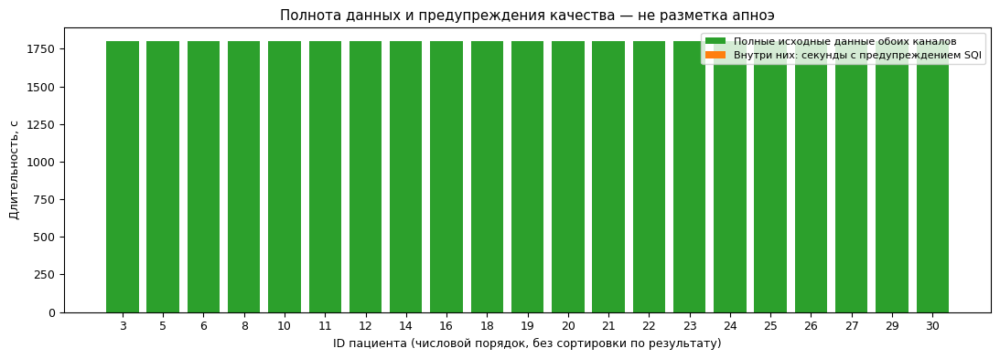

In [3]:
frames=[];processed={};qc=[]
for pid,d in patients.items():
    f,pr=process_patient(pid,d);frames.append(f);processed[pid]=pr
    qc.append(dict(patient=pid,seconds=len(f),warning_seconds=int(pr['ppg_warning'].sum()),
        APNEA_seconds=int(f.target.sum()),APNEA_intervals=len(spans(f.target)),
        HYPOPNEA_seconds=int((f.label=='HYPOPNEA').sum())))
frame=pd.concat(frames,ignore_index=True)
FEATURES={'ФПГ':[c for c in frame if c.startswith('p_')],
          'Поток':[c for c in frame if c.startswith('f_')]}
FEATURES['ФПГ + поток']=FEATURES['ФПГ']+FEATURES['Поток']
y=frame.target.to_numpy();groups=frame.patient.to_numpy()
assert len(frame)==21*1800 and frame.groupby('patient').time_s.apply(lambda x:np.array_equal(x,np.arange(1800))).all()
assert set(frame.label.unique()) <= {'NONE','HYPOPNEA','APNEA-CENTRAL','APNEA-OBSTRUCTIVE','APNEA-MIXED'}
qc=pd.DataFrame(qc);qc.to_csv(RESULTS/'QC.csv',index=False)
print('Секунд:',len(frame),'APNEA:',y.sum(),'доля:',y.mean(),'признаков ФПГ/потока:',len(FEATURES['ФПГ']),len(FEATURES['Поток']))
display(qc)
fig,ax=plt.subplots(figsize=(11,4))
ax.bar(qc.patient.astype(str),qc.seconds,color='#2ca02c',label='Полные исходные данные обоих каналов')
ax.bar(qc.patient.astype(str),qc.warning_seconds,color='#ff7f0e',label='Внутри них: секунды с предупреждением SQI')
ax.set(xlabel='ID пациента (числовой порядок, без сортировки по результату)',ylabel='Длительность, с',title='Полнота данных и предупреждения качества — не разметка апноэ')
ax.legend(fontsize=8);plt.tight_layout();fig.savefig(RESULTS/'QC.png');plt.show()


## Проверка по независимым пациентам

Внешний GroupKFold(5) разделяет **пациентов**, а не секунды. Все прогнозы в отчёте получены только на внешнем тесте. Внутренний GroupKFold(3) внутри train выбирает LR или HGB по average precision. Параметры двух семейств зафиксированы в `CONFIG` до внешнего расчёта. Для ускорения обучение использует каждую вторую секунду train; тест прогнозируется полностью.

На внутренних OOF-оценках train обучается Platt-калибратор. Для потока и сочетания порог выбирается по F1; для ФПГ — по MCC при специфичности ≥95%, с отдельной проверкой пригодности модели. Порог может различаться между внешними фолдами, но не настраивается по меткам тестового пациента. Параметры и ID train/test сохраняются в audit. Порог 0,5 больше не навязан сбалансированной модели.

Важно: эти пациенты уже многократно анализировались в предыдущих версиях. Поэтому это **исследовательская разработка с вложенной проверкой**, а не подтверждающая внешняя валидация. Для доказательства пригодности метода в статье нужен дополнительный нетронутый набор пациентов. Полные ночи и стадии сна отсутствуют; AHI не вычисляется.


## Исправление вырожденного порога ФПГ

Прежний выбор максимального F1 назначал порог 0,05 во всех фолдах и отмечал APNEA почти на всём сигнале. Это вырожденная рабочая точка, а не полезное обнаружение.

Теперь для ФПГ выбирается максимум MCC среди порогов, обеспечивающих **специфичность ≥95% на внутренних OOF-пациентах** после той же постобработки. Кандидаты — квантили train-вероятностей и вариант без положительных прогнозов. Это исследовательское ограничение числа ложных срабатываний, не клинически утверждённый порог. Тестовые метки не используются.

Отдельная проверка дискриминации использует внутренний ROC-AUC≥0,60 и AP≥1,2×долю класса. Если она не пройдена, автоматическое заключение по ФПГ **не выдаётся**. Кандидатные решения остаются на графиках и в таблицах для анализа ошибок, но не трактуются как наличие/отсутствие апноэ. В CSV автоматический вывод при отказе — NaN, а не 0.

Изменение порога не меняет ROC-AUC/AP. Снижение ложных флагов ценой почти полного пропуска APNEA не объявляется улучшением модели. Встроена таблица сравнения с прежним порогом и с тривиальным правилом «всегда нет APNEA». Из этих данных нельзя делать вывод о невозможности любых методов ФПГ; проверяется конкретная модель на конкретной выборке.


**Воспроизводимость между средами:** версии Python/NumPy/scikit-learn и численные библиотеки могут давать немного разные результаты повторного обучения. Равенство текущих вероятностей архивному вектору с допуском 1e-12 не требуется. Архивный запуск показан отдельно; для сравнения двух правил порога используются одни и те же вероятности текущего запуска и train-пороги текущего запуска. Проверки исходных контрольных сумм, формы, конечности вероятностей, разделения пациентов и покрытия теста сохранены.


In [4]:
with threadpool_limits(limits=2):
    probs,preds,raw_probs,audit=nested_predictions(frame,FEATURES)
audit.to_json(RESULTS/'audit.json',orient='records',force_ascii=False,indent=2)
with open(RESULTS/'algorithm_config.json','w') as f:json.dump(CONFIG,f,ensure_ascii=False,indent=2)
for _,row in audit.iterrows():assert not set(row.train_patients)&set(row.test_patients)
display(audit[['model','fold','family','threshold','inner_AP','test_patients']])

ppg_audit=audit[audit.model=='ФПГ']
print('ФПГ: аудит порога и качества. True в insufficient_discrimination = автоматический вывод запрещён.')
display(ppg_audit[['fold','threshold','inner_specificity','inner_sensitivity','inner_MCC','inner_ROC_AUC','inner_AP','inner_prevalence','insufficient_discrimination']].round(4))
ppg_accepted=np.zeros(len(frame),bool)
for _,row in ppg_audit.iterrows():
    ppg_accepted[np.isin(groups,row.test_patients)]=not bool(row.insufficient_discrimination)
print('Доля секунд, для которых ФПГ-модель принята для автоматического вывода:',ppg_accepted.mean())


ФПГ: внешний фолд 1/5, LR, порог 0.07


ФПГ: внешний фолд 2/5, LR, порог 0.09


ФПГ: внешний фолд 3/5, HGB, порог 1.00


ФПГ: внешний фолд 4/5, HGB, порог 0.06


ФПГ: внешний фолд 5/5, LR, порог 0.07


Поток: внешний фолд 1/5, LR, порог 0.20


... (9 outputs left out)

,model,fold,family,threshold,inner_AP,test_patients
0,ФПГ,1,LR,0.073894,0.067964,"[3, 11, 19, 24, 30]"
1,ФПГ,2,LR,0.089022,0.080067,"[10, 18, 23, 29]"
2,ФПГ,3,HGB,1.000000,0.053866,"[8, 16, 22, 27]"
3,ФПГ,4,HGB,0.056513,0.055673,"[6, 14, 21, 26]"
4,ФПГ,5,LR,0.066624,0.056890,"[5, 12, 20, 25]"
5,Поток,1,LR,0.200000,0.701693,"[3, 11, 19, 24, 30]"
6,Поток,2,LR,0.200000,0.652626,"[10, 18, 23, 29]"
7,Поток,3,HGB,0.200000,0.579508,"[8, 16, 22, 27]"
8,Поток,4,LR,0.250000,0.574155,"[6, 14, 21, 26]"
9,Поток,5,LR,0.250000,0.675967,"[5, 12, 20, 25]"


ФПГ: аудит порога и качества. True в insufficient_discrimination = автоматический вывод запрещён.


,fold,threshold,inner_specificity,inner_sensitivity,inner_MCC,inner_ROC_AUC,inner_AP,inner_prevalence,insufficient_discrimination
0,1,0.0739,0.9562,0.0557,0.0146,0.4803,0.0680,0.0692,True
1,2,0.0890,0.9685,0.0599,0.0418,0.4702,0.0801,0.0764,True
2,3,1.0000,1.0000,0.0000,0.0000,0.4924,0.0539,0.0534,True
3,4,0.0565,0.9539,0.0873,0.0433,0.4807,0.0557,0.0535,True
4,5,0.0666,0.9882,0.0360,0.0494,0.4896,0.0569,0.0572,True


Доля секунд, для которых ФПГ-модель принята для автоматического вывода: 0.0


## Проверки реализации

Проверяем, что перестановка врачебных меток не меняет признаки, что короткие прогнозы удаляются по фиксированному правилу, и что один длинный прогноз не получает два совпадения с врачом. Это проверки логики кода, не доказательство клинической точности.


In [5]:
pid=next(iter(patients));d=patients[pid]
a,_=process_patient(pid,d);b,_=process_patient(pid,{**d,'event':np.roll(d['event'],123)})
cols=FEATURES['ФПГ + поток']
np.testing.assert_allclose(a[cols].to_numpy(),b[cols].to_numpy(),equal_nan=True)
prob_test=np.zeros(100);prob_test[10:20]=1;prob_test[40:49]=1
assert spans(postprocess(prob_test,.5))==[(10,20)]
y_test=np.zeros(100,int);y_test[10:20]=1;y_test[25:35]=1
p_test=np.zeros(100,bool);p_test[10:35]=1
mt,_=match_events(y_test,p_test,np.ones(100,int),.3)
assert mt['event_TP']==1 and mt['event_FN']==1
print('PASS: признаки независимы от меток; длительность событий; соответствие 1:1; пациенты train/test не пересекаются')

y_check=np.r_[np.zeros(80,int),np.ones(40,int),np.zeros(80,int)]
g_check=np.ones(len(y_check),int)
chosen,_=select_ppg_operating_point(y_check,np.full(len(y_check),.05),g_check)
assert chosen['predicted_fraction']==0 and chosen['specificity']==1
chosen,_=select_ppg_operating_point(y_check,.1+.8*y_check,g_check)
assert chosen['specificity']==1 and chosen['sensitivity']==1
print('PASS: постоянная неинформативная вероятность не даёт сплошного APNEA; идеальная тестовая вероятность сохраняет обнаружение.')

# Cross-runtime regression: historical numbers may differ by ~0.00018.
current_test=np.linspace(.03,.09,200)
frozen_test=np.clip(current_test+0.00018158,0,1)
assert current_test.shape==frozen_test.shape
assert np.max(np.abs(current_test-frozen_test))>1e-4
current_reference=current_test
assert current_reference is current_test
np.testing.assert_array_equal(segmented_post(current_reference,np.ones(200,int),.06),segmented_post(current_test,np.ones(200,int),.06))
print('PASS: сравнение порогов использует один текущий вектор; отличие от исторических вероятностей не прерывает запуск.')


PASS: признаки независимы от меток; длительность событий; соответствие 1:1; пациенты train/test не пересекаются


PASS: постоянная неинформативная вероятность не даёт сплошного APNEA; идеальная тестовая вероятность сохраняет обнаружение.
PASS: сравнение порогов использует один текущий вектор; отличие от исторических вероятностей не прерывает запуск.


## Честное сравнение с прежним минутным методом

Прежняя схема воспроизводится как baseline: минутные признаки, LR C=1 с балансировкой, Platt-калибровка по внутренним пациентам и порог 0,5. Для обучения прежнего метода сохранено его правило минутных целей (≥10 с APNEA без гипопноэ; отрицательная минута целиком NONE). **При прогнозировании ни один тестовый интервал не скрывается:** минутная вероятность распространяется на все 60 секунд. Внешние тестовые пациенты у старого и нового методов одинаковы.

Таким образом, сравнение «до/после» проводится на одних 37800 секундах с исходной посекундной разметкой, а не с прежней выборкой только удобных минут. Числа baseline закономерно отличаются от старых таблиц, где смешанные минуты вообще отсутствовали. Результаты разных задач напрямую не приравниваются.


In [6]:
import numpy as np,pandas as pd
from scipy import signal
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold

def legacy_features(data):
    rows=[]
    for pid,d in sorted(data.items()):
        for start in range(0,1800,60):
            pp=signal.resample_poly(band(d['signal_pleth'][start:start+60].ravel(),80,.4,9,4),2,5)
            pp/=max(np.sqrt(np.mean(pp**2)),1e-10)
            flow=band(d['PSG_Flow'][start:start+60].ravel(),20,.1,3,2)
            candidates=[]
            for sign in [1,-1]:
                pk,_=signal.find_peaks(sign*pp,distance=11,prominence=max(.15*np.std(pp),1e-8));rr=np.diff(pk)/32
                score=np.mean((rr>=.35)&(rr<=2)) if len(rr) else 0
                candidates.append((score,len(pk),pk))
            score,_,pk=max(candidates,key=lambda z:(z[0],z[1]));rr=np.diff(pk)/32;rr=rr[(rr>=.35)&(rr<=2)]
            lab=d['event'][start:start+60];ap=np.char.startswith(lab,'APNEA');known=np.all((lab=='NONE')|ap)
            target=1 if known and ap.sum()>=10 else (0 if np.all(lab=='NONE') else np.nan)
            r=dict(patient=pid,start_s=start,target=target)
            for prefix,x,fs in [('p_',pp,32),('f_',flow,20)]:
                f,p=signal.welch(x,fs=fs,nperseg=min(len(x),10*fs));amp=np.ptp(x.reshape(60,fs),axis=1)
                r.update({prefix+'amp':np.median(amp),prefix+'amp_cv':np.std(amp)/(np.mean(amp)+1e-10),
                    prefix+'low_amp':np.mean(amp<.2*np.quantile(amp,.75)),prefix+'rms':np.sqrt(np.mean(x*x)),
                    prefix+'freq':f[np.argmax(p)],prefix+'entropy':-np.sum(p/(p.sum()+1e-20)*np.log(p/(p.sum()+1e-20)+1e-20))})
            r.update(p_hr=60/np.median(rr) if len(rr) else np.nan,p_rr_sd=np.std(rr) if len(rr)>1 else np.nan,p_rr_valid=score)
            rows.append(r)
    return pd.DataFrame(rows)

def legacy_model():return make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),LogisticRegression(C=1,class_weight='balanced',max_iter=2000,random_state=42))

def legacy_predictions(data,frame,audit):
    table=legacy_features(data);features={'ФПГ':[c for c in table if c.startswith('p_')],'Поток':[c for c in table if c.startswith('f_')]}
    features['ФПГ + поток']=features['ФПГ']+features['Поток']
    gsec=frame.patient.to_numpy();tsec=frame.time_s.to_numpy();probs={};preds={}
    folds=audit[audit.model=='ФПГ']
    for name,cols in features.items():
        out=np.full(len(frame),np.nan)
        X=table[cols].to_numpy();g=table.patient.to_numpy();yt=table.target.to_numpy()
        for _,row in folds.iterrows():
            te=np.flatnonzero(np.isin(g,row.test_patients));tr=np.flatnonzero(~np.isin(g,row.test_patients)&np.isfinite(yt))
            y=yt[tr].astype(int);inner=np.full(len(tr),np.nan)
            for it,iv in GroupKFold(3).split(X[tr],y,g[tr]):
                m=legacy_model().fit(X[tr[it]],y[it]);inner[iv]=m.predict_proba(X[tr[iv]])[:,1]
            cal=LogisticRegression(C=1e6,max_iter=2000).fit(logit(inner),y)
            m=legacy_model().fit(X[tr],y);prob=cal.predict_proba(logit(m.predict_proba(X[te])[:,1]))[:,1]
            for idx,p in zip(te,prob):
                out[(gsec==g[idx])&(tsec>=table.start_s.iloc[idx])&(tsec<table.start_s.iloc[idx]+60)]=p
        assert np.isfinite(out).all();probs[name]=out;preds[name]=out>=.5
    return probs,preds


In [7]:
with threadpool_limits(limits=2):old_probs,old_preds=legacy_predictions(patients,frame,audit)
METHOD_PROBS={**{'Новая: '+k:v for k,v in probs.items()},**{'Прежняя 60 с: '+k:v for k,v in old_probs.items()}}
METHOD_PREDS={**{'Новая: '+k:v for k,v in preds.items()},**{'Прежняя 60 с: '+k:v for k,v in old_preds.items()}}
# Frozen external OOF predictions from the previous second-level detector.
previous_oof=np.load(io.BytesIO(base64.b64decode('...')),allow_pickle=False)
assert previous_oof['p1'].shape==y.shape
for j,name in [(1,'Поток'),(2,'ФПГ + поток')]:
    METHOD_PROBS['До учёта циклов: '+name]=previous_oof[f'p{j}']
    METHOD_PREDS['До учёта циклов: '+name]=previous_oof[f'd{j}'].astype(bool)

ppg_previous=np.load(io.BytesIO(base64.b64decode('...')),allow_pickle=False)
assert ppg_previous['p'].shape==y.shape
assert np.isfinite(probs['ФПГ']).all() and np.all((probs['ФПГ']>=0)&(probs['ФПГ']<=1))
# A frozen run is a historical benchmark, not a floating-point oracle for new runtimes.
score_drift=np.abs(probs['ФПГ']-ppg_previous['p'])
print('Различие с архивным запуском: max=',float(score_drift.max()),'; mean=',float(score_drift.mean()))
METHOD_PROBS['ФПГ: архивный запуск']=ppg_previous['p']
METHOD_PREDS['ФПГ: архивный запуск']=ppg_previous['d'].astype(bool)
# Isolate threshold policy using the SAME current scores and current train-only
# inner-F1 thresholds, rather than comparing separately trained historical scores.
METHOD_PROBS['ФПГ: прежний порог F1']=probs['ФПГ']
reference_decisions=np.zeros(len(y),bool);reference_coverage=np.zeros(len(y),int)
for _,row in audit[audit.model=='ФПГ'].iterrows():
    ix=np.flatnonzero(np.isin(groups,row.test_patients))
    reference_decisions[ix]=segmented_post(probs['ФПГ'][ix],groups[ix],float(row.reference_F1_threshold))
    reference_coverage[ix]+=1
assert np.all(reference_coverage==1)
METHOD_PREDS['ФПГ: прежний порог F1']=reference_decisions
assert METHOD_PROBS['ФПГ: прежний порог F1'] is probs['ФПГ']

metrics=pd.DataFrame({name:all_metrics(y,p,METHOD_PREDS[name],groups) for name,p in METHOD_PROBS.items()}).T
metrics.to_csv(RESULTS/'metrics.csv')
display(metrics[['ROC_AUC','AP','Brier','sensitivity','specificity','precision','second_F1','event_F1','event_TP','event_FP','event_FN','false_events_per_hour']].round(4))
print('Врачебных интервалов APNEA:',sum(len(spans(y[groups==p])) for p in patients))
print('Тривиальная оценка: всегда 0 → чувствительность 0; всегда 1 → second F1 =',2*y.mean()/(1+y.mean()))
per_patient=[];event_tables=[];strata=[];iou_rows=[]
for name,p in METHOD_PROBS.items():
    dec=METHOD_PREDS[name]
    for pid in patients:
        ix=groups==pid
        per_patient.append(dict(method=name,patient=pid,**all_metrics(y[ix],p[ix],dec[ix],groups[ix])))
    _,ev=match_events(y,dec,groups);ev['method']=name;event_tables.append(ev)
    for threshold in [.1,.3,.5]:
        evm,_=match_events(y,dec,groups,threshold);iou_rows.append(dict(method=name,IoU_threshold=threshold,**evm))
    for label in sorted(frame.label.unique()):
        ix=frame.label.to_numpy()==label
        strata.append(dict(method=name,label=label,seconds=int(ix.sum()),positive_seconds=int(dec[ix].sum()),positive_rate=dec[ix].mean()))
per_patient=pd.DataFrame(per_patient);events=pd.concat(event_tables,ignore_index=True)
per_patient.to_csv(RESULTS/'per_patient.csv',index=False);events.to_csv(RESULTS/'event_matches.csv',index=False)
pd.DataFrame(strata).to_csv(RESULTS/'label_strata.csv',index=False)
pd.DataFrame(iou_rows).to_csv(RESULTS/'IoU_sensitivity.csv',index=False)
with pd.option_context('display.max_rows',150):
    display(per_patient[per_patient.method.str.startswith('Новая:')][['method','patient','sensitivity','precision','second_F1','event_TP','event_FP','event_FN','event_F1']].round(3))
print('Доля положительных прогнозов по каждому типу врачебной метки (для HYPOPNEA/NONE это ложноположительная доля):')
display(pd.DataFrame(strata).query("method.str.startswith('Новая:')",engine='python').round(4))

print('ФПГ — сравнение исследовательских рабочих точек. Ни одна не объявляется надёжным детектором:')
display(metrics.loc[['ФПГ: прежний порог F1','Новая: ФПГ'],['ROC_AUC','AP','second_F1','sensitivity','specificity','precision','FP_seconds','FN_seconds','event_TP','event_FP','event_FN']].round(4))
print('Прежняя/ограниченная доля времени APNEA:',METHOD_PREDS['ФПГ: прежний порог F1'].mean(),preds['ФПГ'].mean())
print('Доля APNEA врача:',y.mean(),'; accuracy тривиального правила «всегда нет APNEA»:',1-y.mean())


Различие с архивным запуском: max= 0.0 ; mean= 0.0


,ROC_AUC,AP,Brier,sensitivity,specificity,precision,second_F1,event_F1,event_TP,event_FP,event_FN,false_events_per_hour
Новая: ФПГ,0.3713,0.0445,0.0587,0.0120,0.9893,0.0685,0.0204,0.0150,1.0,13.0,118.0,1.2381
Новая: Поток,0.9555,0.6141,0.0325,0.7314,0.9711,0.6252,0.6742,0.6667,84.0,49.0,35.0,4.6667
Новая: ФПГ + поток,0.9306,0.4881,0.0393,0.7190,0.9385,0.4354,0.5423,0.5356,79.0,97.0,40.0,9.2381
Прежняя 60 с: ФПГ,0.3226,0.0420,0.0681,0.0000,1.0000,0.0000,0.0000,0.0000,0.0,0.0,119.0,0.0000
Прежняя 60 с: Поток,0.8402,0.2732,0.0750,0.4919,0.9292,0.3142,0.3835,0.0822,6.0,21.0,113.0,2.0000
Прежняя 60 с: ФПГ + поток,0.7971,0.2241,0.0731,0.3730,0.9468,0.3159,0.3421,0.1781,13.0,14.0,106.0,1.3333
До учёта циклов: Поток,0.9559,0.6646,0.0304,0.7524,0.9672,0.6020,0.6688,0.6765,92.0,61.0,27.0,5.8095
До учёта циклов: ФПГ + поток,0.9252,0.5014,0.0391,0.6967,0.9412,0.4387,0.5384,0.5193,74.0,92.0,45.0,8.7619
ФПГ: архивный запуск,0.3713,0.0445,0.0587,0.9692,0.0412,0.0625,0.1174,0.0442,5.0,102.0,114.0,9.7143
ФПГ: прежний порог F1,0.3713,0.0445,0.0587,0.9692,0.0412,0.0625,0.1174,0.0442,5.0,102.0,114.0,9.7143


Врачебных интервалов APNEA: 119
Тривиальная оценка: всегда 0 → чувствительность 0; всегда 1 → second F1 = 0.11649808161841646


,method,patient,sensitivity,precision,second_F1,event_TP,event_FP,event_FN,event_F1
0,Новая: ФПГ,3,0.000,0.000,0.000,0,0,6,0.000
1,Новая: ФПГ,5,0.000,0.000,0.000,0,0,11,0.000
2,Новая: ФПГ,6,0.000,0.000,0.000,0,0,8,0.000
3,Новая: ФПГ,8,0.000,0.000,0.000,0,0,1,0.000
4,Новая: ФПГ,10,NaN,0.000,NaN,0,0,0,NaN
5,Новая: ФПГ,11,NaN,0.000,NaN,0,0,0,NaN
6,Новая: ФПГ,12,0.000,0.000,0.000,0,0,1,0.000
7,Новая: ФПГ,14,NaN,0.000,NaN,0,0,0,NaN
8,Новая: ФПГ,16,0.000,0.000,0.000,0,0,19,0.000
9,Новая: ФПГ,18,NaN,0.000,NaN,0,0,0,NaN


Доля положительных прогнозов по каждому типу врачебной метки (для HYPOPNEA/NONE это ложноположительная доля):


,method,label,seconds,positive_seconds,positive_rate
0,Новая: ФПГ,APNEA-CENTRAL,382,0,0.0000
1,Новая: ФПГ,APNEA-MIXED,570,5,0.0088
2,Новая: ФПГ,APNEA-OBSTRUCTIVE,1386,23,0.0166
3,Новая: ФПГ,HYPOPNEA,3035,62,0.0204
4,Новая: ФПГ,NONE,32427,319,0.0098
5,Новая: Поток,APNEA-CENTRAL,382,246,0.6440
6,Новая: Поток,APNEA-MIXED,570,529,0.9281
7,Новая: Поток,APNEA-OBSTRUCTIVE,1386,935,0.6746
8,Новая: Поток,HYPOPNEA,3035,514,0.1694
9,Новая: Поток,NONE,32427,511,0.0158


ФПГ — сравнение исследовательских рабочих точек. Ни одна не объявляется надёжным детектором:


,ROC_AUC,AP,second_F1,sensitivity,specificity,precision,FP_seconds,FN_seconds,event_TP,event_FP,event_FN
ФПГ: прежний порог F1,0.3713,0.0445,0.1174,0.9692,0.0412,0.0625,34000.0,72.0,5.0,102.0,114.0
Новая: ФПГ,0.3713,0.0445,0.0204,0.0120,0.9893,0.0685,381.0,2310.0,1.0,13.0,118.0


Прежняя/ограниченная доля времени APNEA: 0.9594179894179894 0.01082010582010582
Доля APNEA врача: 0.06185185185185185 ; accuracy тривиального правила «всегда нет APNEA»: 0.9381481481481482


## Как определяется совпадение события

Посекундно TP — и врач, и алгоритм APNEA; FN — врач APNEA, алгоритм нет; FP — алгоритм APNEA, врач нет; TN — оба нет.

Для оценки эпизодов сначала выделяются непрерывные интервалы. Степень перекрытия **IoU = длительность пересечения / длительность объединения**. Основной критерий IoU≥0,30, дополнительно публикуются 0,10 и 0,50. Это исследовательский критерий совпадения, не допуск AASM. Ищется взаимно-однозначное соответствие: один прогноз не может засчитаться за два врачебных события. Отдельно указаны пропуски, лишние эпизоды, ложные эпизоды в час и средние ошибки начала/окончания **только у совпавших** событий. Для пропущенных событий ошибка границы не определяется.

Красный врачебный интервал и близкий прогноз могут иметь одновременно совпавшую середину, пропущенное начало и ложное продление — это видно в посекундной карте ошибок. На границе фрагмента интервалы могут быть обрезаны; они сохраняются в оценке.


In [8]:
display(pd.DataFrame(iou_rows).query("method.str.startswith('Новая:')",engine='python').round(3))
print('Пример таблицы соответствий; полная таблица сохраняется в event_matches.csv')
display(events[events.method=='Новая: Поток'].head(30).round(3))


,method,IoU_threshold,event_TP,event_FP,event_FN,event_precision,event_recall,event_F1,onset_MAE_s,offset_MAE_s
0,Новая: ФПГ,0.1,3,11,116,0.214,0.025,0.045,42.333,7.000
1,Новая: ФПГ,0.3,1,13,118,0.071,0.008,0.015,9.000,5.000
2,Новая: ФПГ,0.5,0,14,119,0.000,0.000,0.000,NaN,NaN
3,Новая: Поток,0.1,84,49,35,0.632,0.706,0.667,2.345,1.524
4,Новая: Поток,0.3,84,49,35,0.632,0.706,0.667,2.345,1.524
5,Новая: Поток,0.5,84,49,35,0.632,0.706,0.667,2.345,1.524
6,Новая: ФПГ + поток,0.1,80,96,39,0.455,0.672,0.542,3.400,2.562
7,Новая: ФПГ + поток,0.3,79,97,40,0.449,0.664,0.536,3.380,2.139
8,Новая: ФПГ + поток,0.5,74,102,45,0.420,0.622,0.502,2.649,1.811


Пример таблицы соответствий; полная таблица сохраняется в event_matches.csv


,patient,status,doctor_start,doctor_end,algorithm_start,algorithm_end,IoU,method
132,3,matched,641.0,653.0,639.0,653.0,0.857,Новая: Поток
133,3,matched,663.0,682.0,661.0,684.0,0.826,Новая: Поток
134,3,matched,694.0,712.0,691.0,709.0,0.714,Новая: Поток
135,3,matched,827.0,842.0,825.0,843.0,0.833,Новая: Поток
136,3,matched,890.0,908.0,888.0,905.0,0.750,Новая: Поток
137,3,matched,920.0,939.0,917.0,934.0,0.636,Новая: Поток
138,3,false_alarm,NaN,NaN,857.0,881.0,NaN,Новая: Поток
139,3,false_alarm,NaN,NaN,1079.0,1093.0,NaN,Новая: Поток
140,5,matched,735.0,750.0,728.0,749.0,0.636,Новая: Поток
141,5,matched,832.0,847.0,830.0,847.0,0.882,Новая: Поток


## ROC, PR и калибровка

Кривые используют только внешние OOF-вероятности на всех секундах. AP — average precision, а не трапециевидная площадь PR. Предельная точность без навыка зависит от распространённости класса, поэтому accuracy отдельно недостаточно. Brier меньше — лучше; калибровочные корзины квантильные. Калибровка оценивается на внешнем тесте; обучается только внутри train.


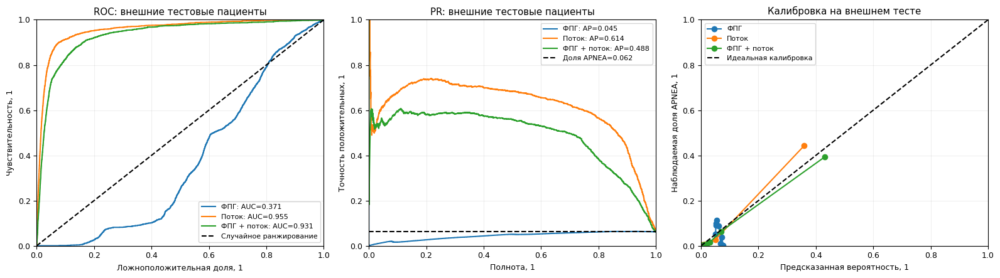

,Brier до калибровки,Brier после калибровки
ФПГ,0.17297,0.05874
Поток,0.06045,0.03250
ФПГ + поток,0.04230,0.03932


In [9]:
from sklearn.metrics import roc_curve,precision_recall_curve
from sklearn.calibration import calibration_curve
COLORS={'ФПГ':'#1f77b4','Поток':'#ff7f0e','ФПГ + поток':'#2ca02c'}
fig,axs=plt.subplots(1,3,figsize=(16,4.5))
for name,p in probs.items():
    fpr,tpr,_=roc_curve(y,p);precision,recall,_=precision_recall_curve(y,p)
    axs[0].plot(fpr,tpr,color=COLORS[name],label=f'{name}: AUC={roc_auc_score(y,p):.3f}')
    axs[1].plot(recall,precision,color=COLORS[name],label=f'{name}: AP={average_precision_score(y,p):.3f}')
    observed,mean=calibration_curve(y,p,n_bins=8,strategy='quantile')
    axs[2].plot(mean,observed,'o-',color=COLORS[name],label=name)
axs[0].plot([0,1],[0,1],'k--',label='Случайное ранжирование')
axs[1].axhline(y.mean(),color='black',ls='--',label=f'Доля APNEA={y.mean():.3f}')
axs[2].plot([0,1],[0,1],'k--',label='Идеальная калибровка')
for ax,title,xl,yl in zip(axs,['ROC: внешние тестовые пациенты','PR: внешние тестовые пациенты','Калибровка на внешнем тесте'],
    ['Ложноположительная доля, 1','Полнота, 1','Предсказанная вероятность, 1'],
    ['Чувствительность, 1','Точность положительных, 1','Наблюдаемая доля APNEA, 1']):
    ax.set(title=title,xlabel=xl,ylabel=yl,xlim=(0,1),ylim=(0,1));ax.legend(fontsize=8);ax.grid(alpha=.2)
plt.tight_layout();fig.savefig(RESULTS/'ROC_PR_calibration.png');plt.show()
display(pd.DataFrame({'Brier до калибровки':{k:brier_score_loss(y,p) for k,p in raw_probs.items()},
                      'Brier после калибровки':{k:brier_score_loss(y,p) for k,p in probs.items()}}).round(5))


## 95% доверительные интервалы и проверка улучшения

1000 парных кластерных bootstrap-выборок пациентов с возвращением. Все секунды выбранного пациента сохраняются вместе, для всех методов используются одни и те же перевыбранные пациенты. Событийные TP/FP/FN суммируются по пациентам, поэтому повторное выпадение пациента не склеивает его события через границу копий.

Интервалы условны на уже обученных OOF-моделях, без переобучения внутри bootstrap; полная неопределённость разработки не учитывается. Это exploratory CI, без поправки на множественные сравнения. Заявление об улучшении допускается только для конкретной метрики, у которой парный CI разности исключает 0 в нужную сторону. Для сочетания отдельно проверяется добавочная ценность относительно потока.


In [10]:
import numpy as np,pandas as pd

def clustered_ci(y,g,method_probs,method_preds,per_patient,metrics,names,n_boot=1000):
    ids=np.unique(g);id_index={pid:i for i,pid in enumerate(ids)}
    gi=np.array([id_index[p] for p in g]);rng=np.random.default_rng(42)
    cache={}
    for name,p in method_probs.items():
        order=np.argsort(p,kind='stable')[::-1];ps=p[order]
        ends=np.r_[np.flatnonzero(np.diff(ps)!=0),len(y)-1]
        st=per_patient[per_patient.method==name].set_index('patient').loc[ids]
        tp=st.TP_seconds.to_numpy();fp=st.FP_seconds.to_numpy();fn=st.FN_seconds.to_numpy()
        nn=np.bincount(gi,minlength=len(ids));tn=nn-tp-fp-fn
        bs=np.bincount(gi,weights=(p-y)**2,minlength=len(ids))
        cache[name]=(order,ends,gi[order],y[order],tp,fp,fn,tn,bs,st.event_TP.to_numpy(),st.event_FP.to_numpy(),st.event_FN.to_numpy(),nn)
    keys=['ROC_AUC','AP','Brier','second_F1','sensitivity','specificity','precision','accuracy','event_F1','event_recall','false_events_per_hour']
    rep={name:[] for name in method_probs}
    for b in range(n_boot):
        # Same RNG draws as explicit patient resampling; counts avoid huge repeated tables.
        sampled=rng.choice(ids,len(ids),replace=True)
        mult=np.bincount([id_index[p] for p in sampled],minlength=len(ids))
        for name,ca in cache.items():
            order,ends,gis,ys,TP,FP,FN,TN,BS,ETP,EFP,EFN,NN=ca
            ww=mult[gis];ct=np.cumsum(ww*ys)[ends];cf=np.cumsum(ww*(1-ys))[ends]
            pos=ct[-1];neg=cf[-1]
            ap=np.sum(np.diff(np.r_[0,ct])*np.divide(ct,ct+cf,out=np.zeros_like(ct,dtype=float),where=(ct+cf)>0))/pos if pos else np.nan
            auc=np.trapezoid(np.r_[0,ct]/pos,np.r_[0,cf]/neg) if pos and neg else np.nan
            tp,fp,fn,tn,bs,etp,efp,efn,nn=[np.dot(mult,v) for v in [TP,FP,FN,TN,BS,ETP,EFP,EFN,NN]]
            rep[name].append(dict(ROC_AUC=auc,AP=ap,Brier=bs/nn,
                second_F1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan,
                sensitivity=tp/(tp+fn) if tp+fn else np.nan,specificity=tn/(tn+fp) if tn+fp else np.nan,
                precision=tp/(tp+fp) if tp+fp else 0,accuracy=(tp+tn)/nn,
                event_F1=2*etp/(2*etp+efp+efn) if 2*etp+efp+efn else np.nan,
                event_recall=etp/(etp+efn) if etp+efn else np.nan,false_events_per_hour=efp/(nn/3600)))
    ci=[];delta=[]
    for name,reps in rep.items():
        df=pd.DataFrame(reps)
        for key in keys:
            lo,hi=np.nanpercentile(df[key],[2.5,97.5]);ci.append(dict(method=name,metric=key,estimate=metrics.loc[name,key],low=lo,high=hi,valid_bootstrap=int(df[key].notna().sum())))
    contrasts=[('Новая: '+k,'Прежняя 60 с: '+k) for k in names]+[('Новая: ФПГ + поток','Новая: Поток'),('Новая: Поток','До учёта циклов: Поток'),('Новая: ФПГ + поток','До учёта циклов: ФПГ + поток'),('Новая: ФПГ','ФПГ: прежний порог F1')]
    for a,b in contrasts:
        for key in keys:
            dif=pd.DataFrame(rep[a])[key]-pd.DataFrame(rep[b])[key];lo,hi=np.nanpercentile(dif,[2.5,97.5])
            delta.append(dict(comparison=a+' MINUS '+b,metric=key,estimate=metrics.loc[a,key]-metrics.loc[b,key],low=lo,high=hi,
                improvement_supported=bool(hi<0) if key in ['Brier','false_events_per_hour'] else bool(lo>0)))
    return pd.DataFrame(ci),pd.DataFrame(delta)

CI,differences=clustered_ci(y,groups,METHOD_PROBS,METHOD_PREDS,per_patient,metrics,list(probs),n_boot=1000)
CI.to_csv(RESULTS/'CI.csv',index=False);differences.to_csv(RESULTS/'paired_differences.csv',index=False)
display(CI[CI.method.str.startswith('Новая:')].round(4))
display(differences[differences.metric.isin(['second_F1','event_F1','AP','Brier'])].round(4))


,method,metric,estimate,low,high,valid_bootstrap
0,Новая: ФПГ,ROC_AUC,0.3713,0.2315,0.5125,1000
1,Новая: ФПГ,AP,0.0445,0.0169,0.0859,1000
2,Новая: ФПГ,Brier,0.0587,0.0257,0.1022,1000
3,Новая: ФПГ,second_F1,0.0204,0.0000,0.0537,1000
4,Новая: ФПГ,sensitivity,0.0120,0.0000,0.0442,1000
5,Новая: ФПГ,specificity,0.9893,0.9667,1.0000,1000
6,Новая: ФПГ,precision,0.0685,0.0000,0.0685,1000
7,Новая: ФПГ,accuracy,0.9288,0.8722,0.9724,1000
8,Новая: ФПГ,event_F1,0.0150,0.0000,0.0374,1000
9,Новая: ФПГ,event_recall,0.0084,0.0000,0.0253,1000


,comparison,metric,estimate,low,high,improvement_supported
1,Новая: ФПГ MINUS Прежняя 60 с: ФПГ,AP,0.0025,-0.0069,0.0131,False
2,Новая: ФПГ MINUS Прежняя 60 с: ФПГ,Brier,-0.0094,-0.0164,-0.0006,True
3,Новая: ФПГ MINUS Прежняя 60 с: ФПГ,second_F1,0.0204,0.0000,0.0537,False
8,Новая: ФПГ MINUS Прежняя 60 с: ФПГ,event_F1,0.0150,0.0000,0.0374,False
12,Новая: Поток MINUS Прежняя 60 с: Поток,AP,0.3409,0.1766,0.4825,True
13,Новая: Поток MINUS Прежняя 60 с: Поток,Brier,-0.0425,-0.0755,-0.0186,True
14,Новая: Поток MINUS Прежняя 60 с: Поток,second_F1,0.2907,0.1857,0.4556,True
19,Новая: Поток MINUS Прежняя 60 с: Поток,event_F1,0.5845,0.4057,0.7155,True
23,Новая: ФПГ + поток MINUS Прежняя 60 с: ФПГ + п...,AP,0.2639,0.1095,0.4179,True
24,Новая: ФПГ + поток MINUS Прежняя 60 с: ФПГ + п...,Brier,-0.0338,-0.0615,-0.0130,True


## Все 30 минут каждого пациента: врач, прогноз и ошибки

Каждый пациент показан в числовом порядке, без отбора по успеху модели. Красная линия/заливка — **врачебная метка APNEA**; оранжевый фон на сигнальных панелях — врачебная HYPOPNEA. На панели вероятностей три модели и их пороги, выбранные только на обучающих пациентах.

На трёх нижних панелях красная пунктирная линия — врач; цветная сплошная — алгоритм. Фон: **зелёный TP** (оба APNEA), **жёлтый FN** (пропуск), **фиолетовый FP** (ложное срабатывание), **светло-серый TN** (оба не APNEA). Эти категории посекундные, а не число совпавших событий. Крестиков и минутного сдвига больше нет. Если нет ни врачебных APNEA, ни положительных прогнозов, F1 не определён (NaN); это не пропуск апноэ. Нулевые TP/FP/FN показывают, что положительных событий для проверки нет.

После каждого полного обзора строится увеличение первого врачебного APNEA (или первых 120 с, если APNEA нет). Это правило выбора только иллюстрации, без изменения обучения/оценки. Увеличение показывает исходный ФПГ, обработанный сигнал с найденными пиками, поток и решения по потоку. На обзорной панели пульса — **только ЧСС из ФПГ**, без ЭКГ.


Легенда цветов повторена **под каждой панелью**, вне данных. Фиолетовый фон означает только ложноположительные секунды: алгоритм APNEA, врач не APNEA. Кривая потока теперь тёмно-серая. В увеличении добавлены чёрные кружки/треугольники максимумов/минимумов дыхательных волн и отдельная частота дыхания. Это не метки врача.


Панель ФПГ показывает **отклонённый исследовательский кандидат** с ограниченным порогом. Его нулевая линия не означает доказанное отсутствие APNEA. Автоматический вывод по непринятой модели не выдаётся. Врачебная линия и ошибки кандидата сохранены, чтобы не скрывать пропуски.


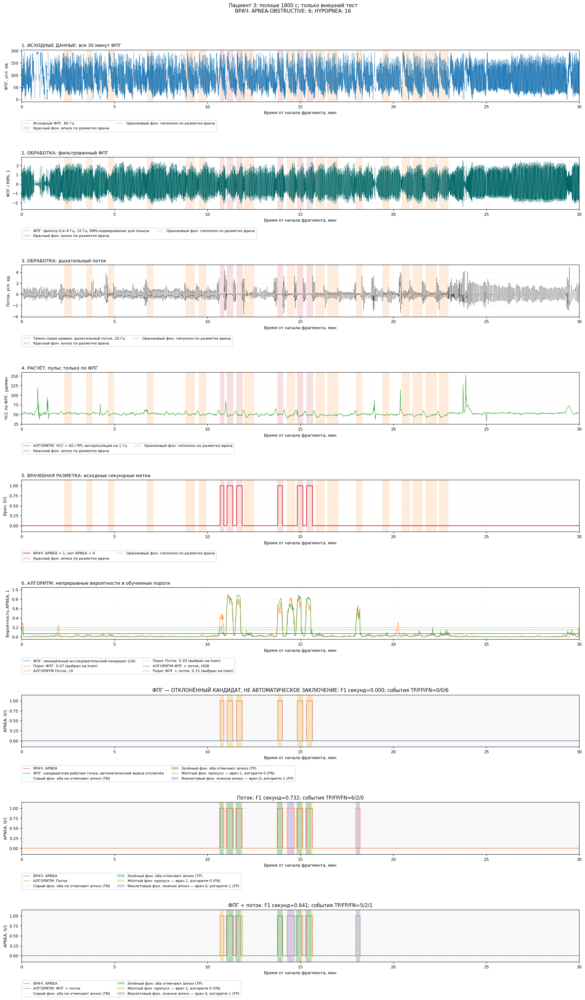

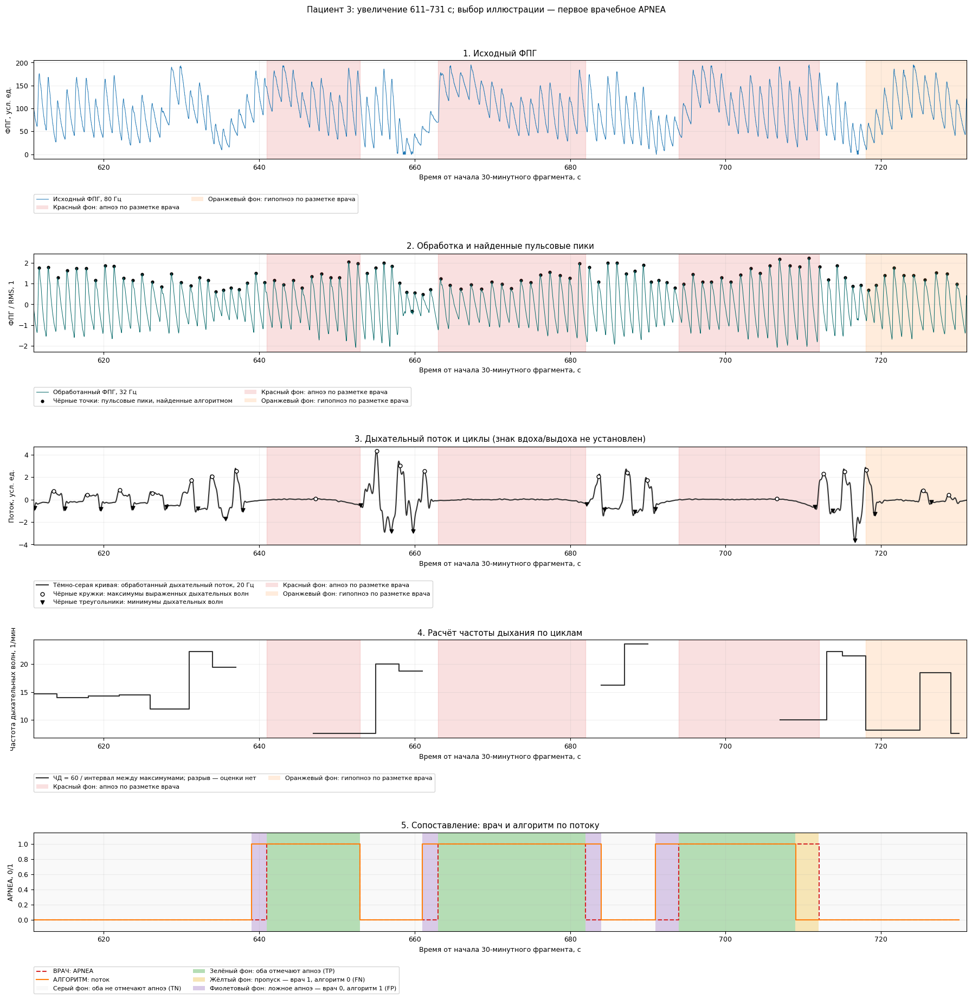

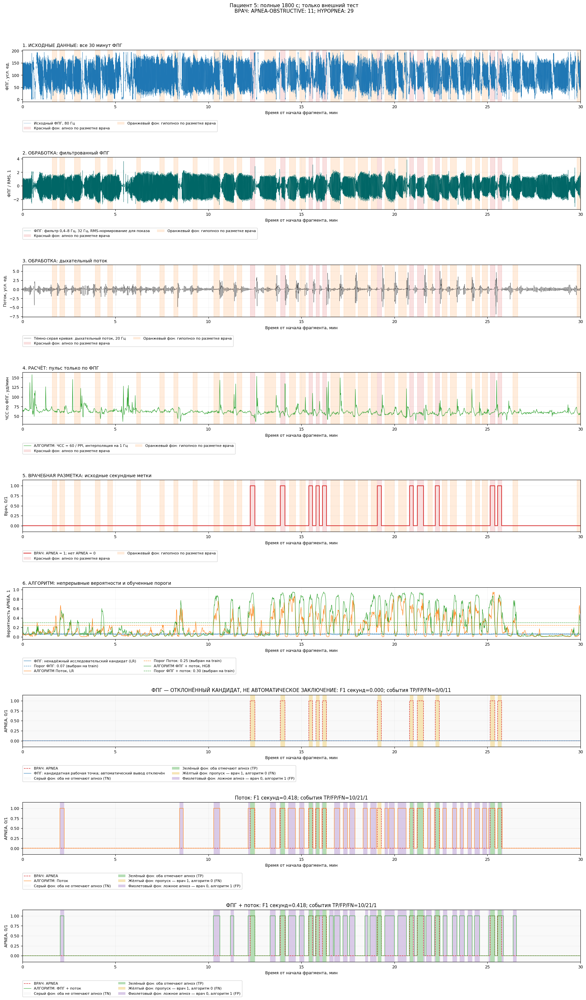

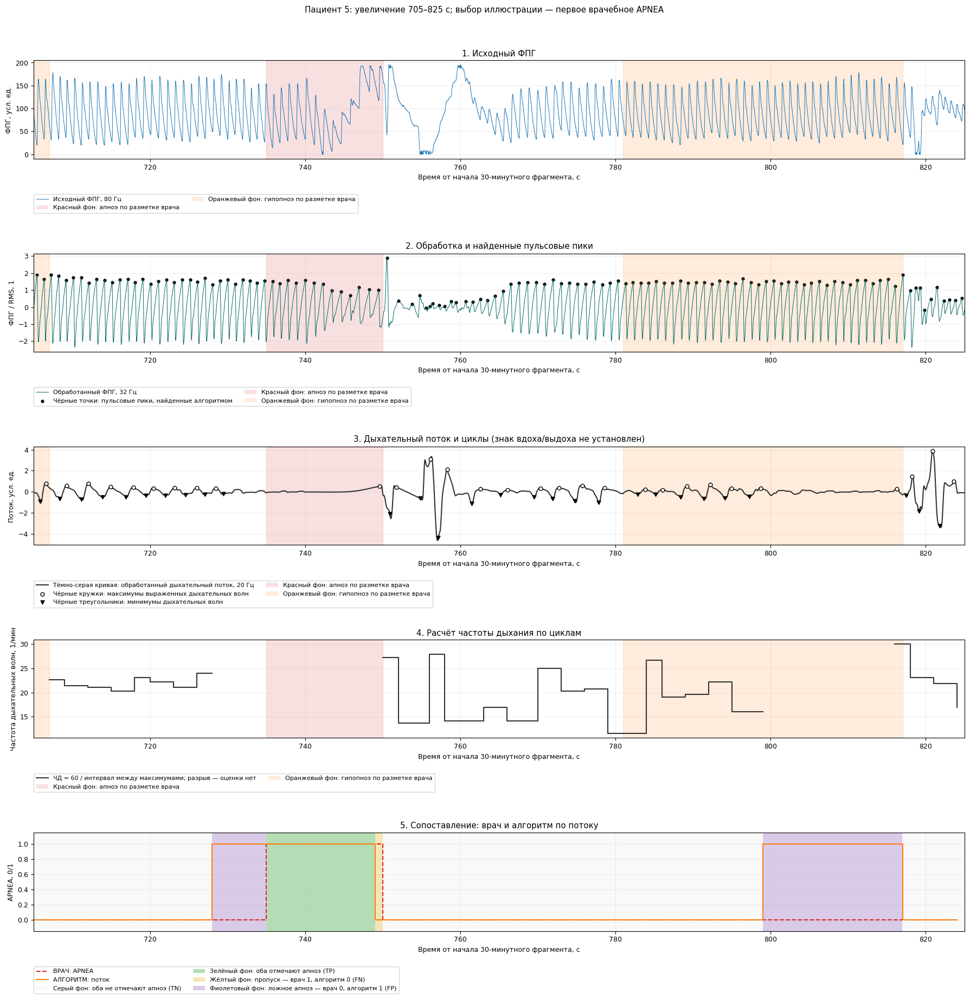

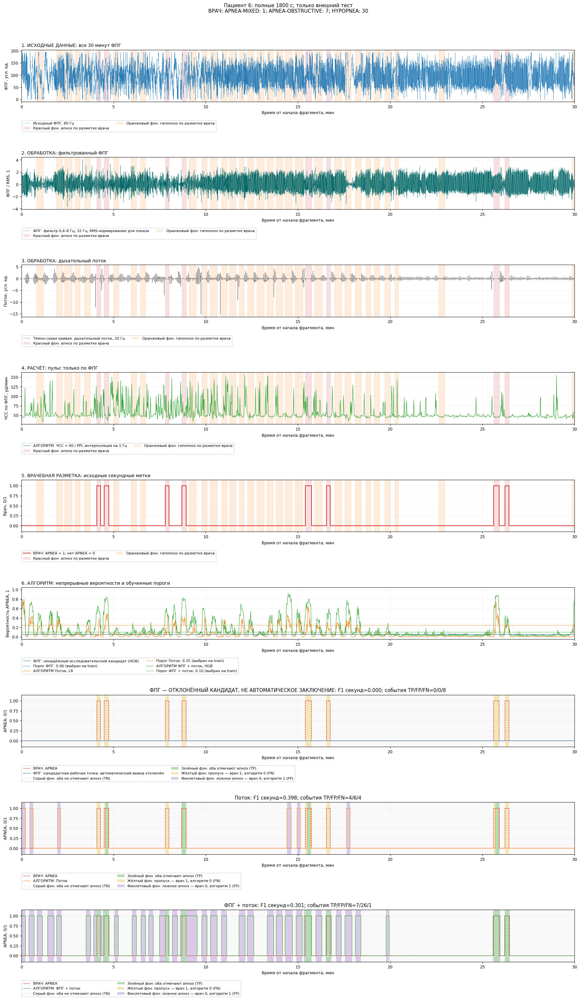

...

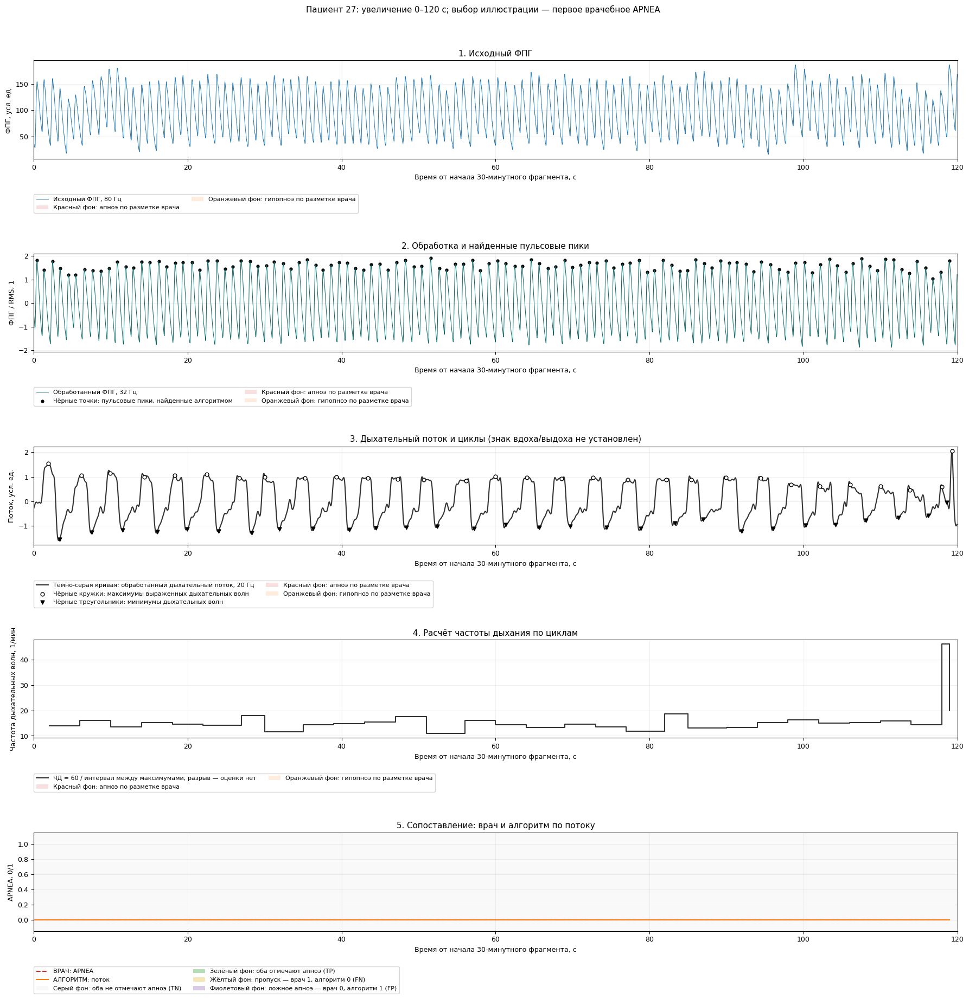

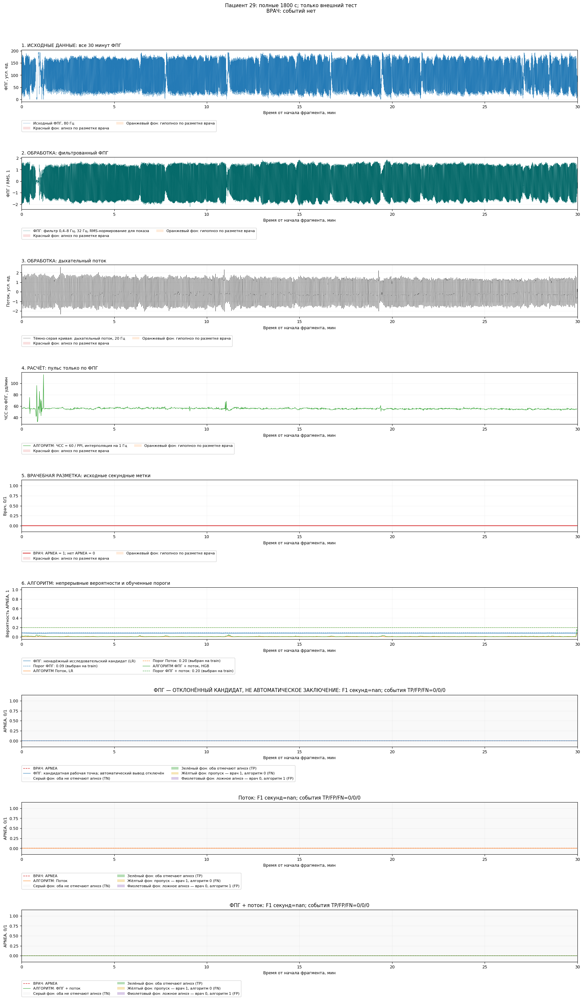

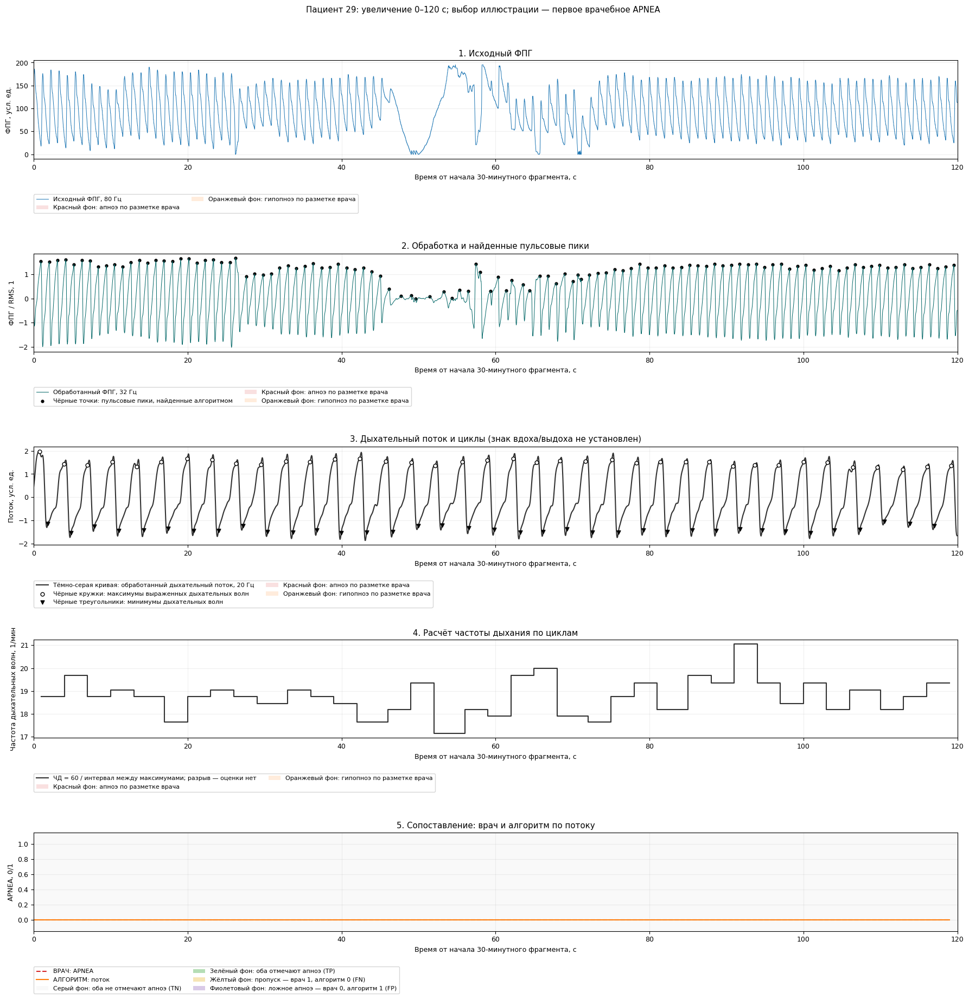

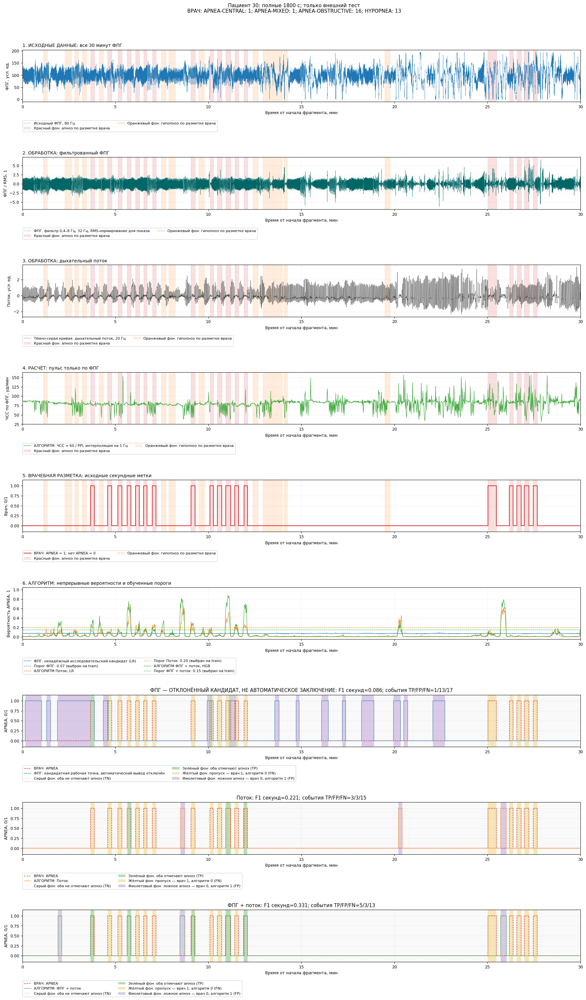

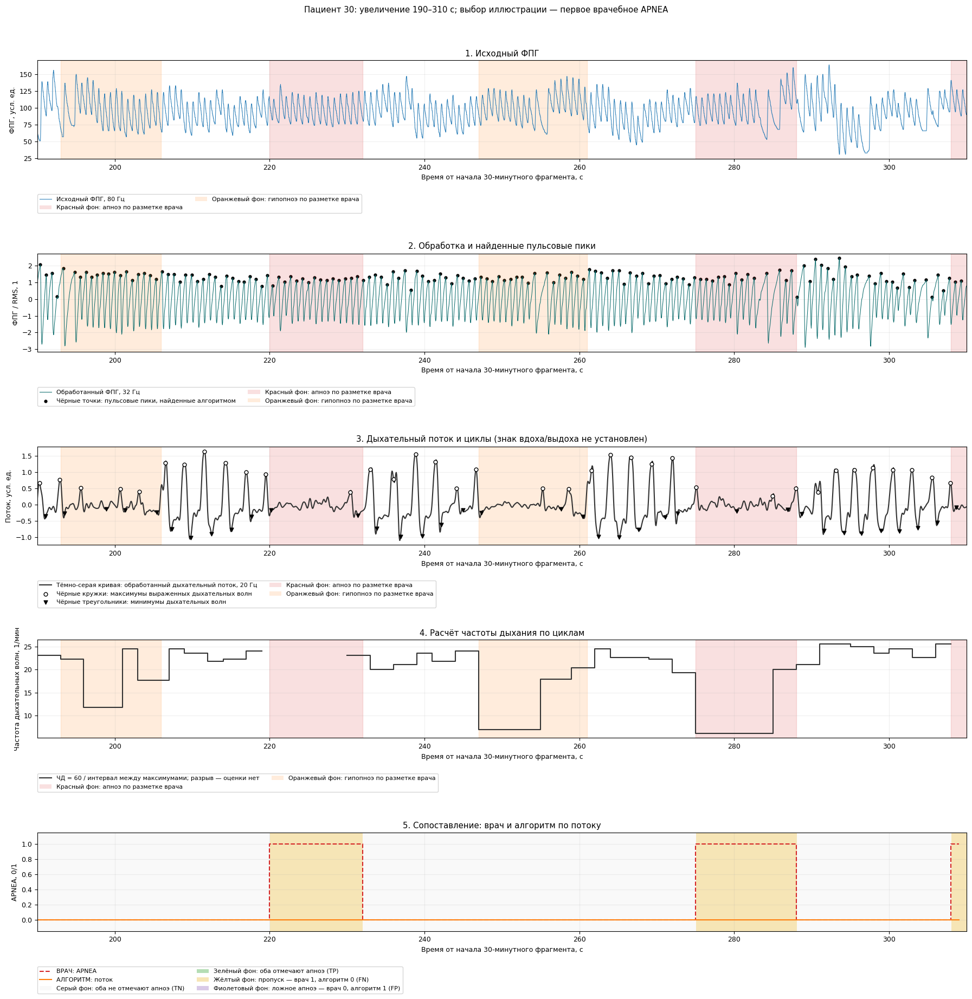

In [11]:
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap
ERR_COLORS=['#eeeeee','#2ca02c','#e8b630','#9467bd']
def shade_doctor(ax,labels,offset=0,scale=60):
    ax._color_explanations=[
        Patch(facecolor='#d62728',alpha=.14,label='Красный фон: апноэ по разметке врача'),
        Patch(facecolor='#ff7f0e',alpha=.14,label='Оранжевый фон: гипопноэ по разметке врача')]
    for mask,color in [(np.char.startswith(labels,'APNEA'),'#d62728'),(labels=='HYPOPNEA','#ff7f0e')]:
        for a,b in spans(mask):ax.axvspan((a+offset)/scale,(b+offset)/scale,color=color,alpha=.14)
def err_background(ax,yy,dd,start=0,scale=60):
    ax._color_explanations=[
        Patch(facecolor=ERR_COLORS[0],alpha=.35,label='Серый фон: оба не отмечают апноэ (TN)'),
        Patch(facecolor=ERR_COLORS[1],alpha=.35,label='Зелёный фон: оба отмечают апноэ (TP)'),
        Patch(facecolor=ERR_COLORS[2],alpha=.35,label='Жёлтый фон: пропуск — врач 1, алгоритм 0 (FN)'),
        Patch(facecolor=ERR_COLORS[3],alpha=.35,label='Фиолетовый фон: ложное апноэ — врач 0, алгоритм 1 (FP)')]
    cat=np.where(yy&dd,1,np.where(yy&~dd,2,np.where(~yy&dd,3,0)))
    ax.imshow(cat.reshape(1,-1),aspect='auto',interpolation='nearest',origin='lower',
        extent=[start/scale,(start+len(cat))/scale,-.15,1.15],cmap=ListedColormap(ERR_COLORS),vmin=0,vmax=3,alpha=.35)
def panel_legend(ax):
    handles,labels=ax.get_legend_handles_labels()
    handles+=getattr(ax,'_color_explanations',[])
    ax.legend(handles=handles,loc='upper left',bbox_to_anchor=(0,-.36),
              ncol=2,fontsize=8,frameon=True,borderaxespad=0)
def save_show(fig,name):
    fig.savefig(RESULTS/(name+'.png'),dpi=120,bbox_inches='tight');plt.show()
for pid,d in patients.items():
    ix=np.flatnonzero(groups==pid);yy=y[ix].astype(bool);pr=processed[pid]
    labels=d['event'].astype(str);t=np.arange(1800)/60
    counts={label:len(spans(labels==label)) for label in np.unique(labels) if label!='NONE'}
    text='; '.join(f'{k}: {v}' for k,v in counts.items()) or 'событий нет'
    fig,axs=plt.subplots(9,1,figsize=(18,32))
    axs[0].plot(np.arange(144000)/80/60,d['signal_pleth'].ravel(),color='#1f77b4',lw=.35,label='Исходный ФПГ, 80 Гц')
    axs[0].set_ylabel('ФПГ, усл. ед.')
    pp=pr['ppg'];ppnorm=pp/max(np.sqrt(np.mean(pp**2)),1e-10)
    axs[1].plot(np.arange(len(pp))/32/60,ppnorm,color='#006666',lw=.35,label='ФПГ: фильтр 0,4–8 Гц, 32 Гц, RMS-нормирование для показа')
    axs[1].set_ylabel('ФПГ / RMS, 1')
    axs[2].plot(np.arange(36000)/20/60,pr['flow'],color='#333333',lw=.4,label='Тёмно-серая кривая: дыхательный поток, 20 Гц')
    axs[2].set_ylabel('Поток, усл. ед.')
    axs[3].plot(t,pr['hr'],color='#2ca02c',lw=.8,label='АЛГОРИТМ: ЧСС = 60 / PPI, интерполяция на 1 Гц')
    axs[3].set_ylabel('ЧСС по ФПГ, уд/мин')
    axs[4].step(t,yy,where='post',color='#d62728',label='ВРАЧ: APNEA = 1; нет APNEA = 0')
    axs[4].set(ylabel='Врач, 0/1',ylim=(-.15,1.15))
    for name,p in probs.items():
        row=audit[(audit.model==name)&audit.test_patients.apply(lambda ps:pid in ps)].iloc[0]
        axs[5].plot(t,p[ix],color=COLORS[name],lw=.8,label=(f'ФПГ: ненадёжный исследовательский кандидат ({row.family})' if name=='ФПГ' else f'АЛГОРИТМ {name}, {row.family}'))
        axs[5].axhline(row.threshold,color=COLORS[name],ls='--',lw=.8,label=f'Порог {name}: {row.threshold:.2f} (выбран на train)')
    axs[5].set(ylabel='Вероятность APNEA, 1',ylim=(-.05,1.05))
    for ax,name in zip(axs[6:],probs):
        dd=preds[name][ix];err_background(ax,yy,dd)
        ax.step(t,yy,where='post',color='#d62728',ls='--',lw=1,label='ВРАЧ: APNEA')
        ax.step(t,dd,where='post',color=COLORS[name],lw=.8,label=('ФПГ: кандидатная рабочая точка; автоматический вывод отключён' if name=='ФПГ' else 'АЛГОРИТМ: '+name))
        met=all_metrics(y[ix],probs[name][ix],dd,groups[ix])
        ax.set(ylabel='APNEA, 0/1',ylim=(-.15,1.15),title=f'{name}'+(' — ОТКЛОНЁННЫЙ КАНДИДАТ, НЕ АВТОМАТИЧЕСКОЕ ЗАКЛЮЧЕНИЕ' if name=='ФПГ' else '')+f': F1 секунд={met["second_F1"]:.3f}; события TP/FP/FN={int(met["event_TP"])}/{int(met["event_FP"])}/{int(met["event_FN"])}')
    titles=['1. ИСХОДНЫЕ ДАННЫЕ: все 30 минут ФПГ','2. ОБРАБОТКА: фильтрованный ФПГ',
        '3. ОБРАБОТКА: дыхательный поток','4. РАСЧЁТ: пульс только по ФПГ',
        '5. ВРАЧЕБНАЯ РАЗМЕТКА: исходные секундные метки',
        '6. АЛГОРИТМ: непрерывные вероятности и обученные пороги']
    for ax,title in zip(axs[:6],titles):ax.set_title(title,loc='left',fontsize=10)
    for ax in axs[:5]:shade_doctor(ax,labels)
    for ax in axs:
        ax.set(xlabel='Время от начала фрагмента, мин',xlim=(0,30));ax.set_xticks(np.arange(0,31,5));ax.grid(alpha=.15);panel_legend(ax)
    fig.suptitle(f'Пациент {pid}: полные 1800 с; только внешний тест\nВРАЧ: {text}',fontsize=11)
    fig.tight_layout(rect=(0,.015,1,.96));save_show(fig,f'patient_{pid}_30min')
    ev=spans(yy);a=max(0,ev[0][0]-30) if ev else 0;b=min(1800,a+120)
    fig,axs=plt.subplots(5,1,figsize=(18,19))
    tt=np.arange(a,b)
    axs[0].plot(np.arange(a*80,b*80)/80,d['signal_pleth'][a:b].ravel(),color='#1f77b4',lw=.7,label='Исходный ФПГ, 80 Гц');axs[0].set_ylabel('ФПГ, усл. ед.')
    axs[1].plot(np.arange(a*32,b*32)/32,ppnorm[a*32:b*32],color='#006666',lw=.7,label='Обработанный ФПГ, 32 Гц')
    pk=pr['peaks'];pk=pk[(pk>=a*32)&(pk<b*32)]
    axs[1].scatter(pk/32,ppnorm[pk],s=12,color='#000000',label='Чёрные точки: пульсовые пики, найденные алгоритмом');axs[1].set_ylabel('ФПГ / RMS, 1')
    axs[2].plot(np.arange(a*20,b*20)/20,pr['flow'][a*20:b*20],color='#333333',label='Тёмно-серая кривая: обработанный дыхательный поток, 20 Гц');axs[2].set_ylabel('Поток, усл. ед.')
    br=pr['breaths']
    bp=br['peaks'];bp=bp[(bp>=a*20)&(bp<b*20)]
    bt=br['troughs'];bt=bt[(bt>=a*20)&(bt<b*20)]
    axs[2].scatter(bp/20,pr['flow'][bp],s=24,facecolors='white',edgecolors='black',zorder=5,label='Чёрные кружки: максимумы выраженных дыхательных волн')
    axs[2].scatter(bt/20,pr['flow'][bt],s=24,marker='v',color='black',zorder=5,label='Чёрные треугольники: минимумы дыхательных волн')
    axs[3].step(tt,br['rate'][a:b],where='post',color='#333333',label='ЧД = 60 / интервал между максимумами; разрыв — оценки нет')
    axs[3].set_ylabel('Частота дыхательных волн, 1/мин')
    dd=preds['Поток'][ix][a:b];err_background(axs[4],yy[a:b],dd,start=a,scale=1)
    axs[4].step(tt,yy[a:b],where='post',color='#d62728',ls='--',label='ВРАЧ: APNEA')
    axs[4].step(tt,dd,where='post',color=COLORS['Поток'],label='АЛГОРИТМ: поток');axs[4].set(ylabel='APNEA, 0/1',ylim=(-.15,1.15))
    for ax,title in zip(axs,['1. Исходный ФПГ','2. Обработка и найденные пульсовые пики','3. Дыхательный поток и циклы (знак вдоха/выдоха не установлен)','4. Расчёт частоты дыхания по циклам','5. Сопоставление: врач и алгоритм по потоку']):
        ax.set(title=title,xlabel='Время от начала 30-минутного фрагмента, с',xlim=(a,b));ax.grid(alpha=.2)
    for ax in axs[:4]:shade_doctor(ax,labels[a:b],offset=a,scale=1)
    for ax in axs:panel_legend(ax)
    fig.suptitle(f'Пациент {pid}: увеличение {a}–{b} с; выбор иллюстрации — первое врачебное APNEA')
    fig.tight_layout(rect=(0,0,1,.96));save_show(fig,f'patient_{pid}_detail')


## Почему возникают ложные срабатывания: проверка гипотез

Пока врачебные метки приняты за эталон, FP — ошибка алгоритма относительно этого эталона. Сам по себе низкий носовой поток не доказывает, что врач пропустил апноэ. Причины могут включать гипопноэ, изменение дыхания/датчика и ошибки модели. Для независимого клинического пересмотра нужны исходные PSG-каналы (включая дыхательные усилия, дополнительные данные потока, SpO₂/стадии сна) и повторная слепая оценка специалиста. В переданном архиве полного набора PSG нет.

Ниже каждый лишний интервал разделяется по пересечению с APNEA, HYPOPNEA или только NONE врача. Измеряются огибающая потока, длительность сильного падения, выраженные волны и наибольший промежуток между ними. Отсутствие найденных волн — свойство выбранного детектора, не доказанное отсутствие дыхания. Огибающая и волны получены из того же канала, который использует модель: это объяснение её работы, а не независимое подтверждение диагноза.

Также проверяются сдвиги −15…+15 с. Этот перебор только описательный: тестовые прогнозы **не сдвигаются**, лучшая найденная оценка не заменяет основную метрику. Нормальное прохождение потока через ноль не означает апноэ; текущая модель использует огибающую/контекст и сохраняет интервалы ≥10 с.


Каждое лишнее событие отнесено к одной категории; пересечение с HYPOPNEA не означает APNEA.


events  seconds  median_waves  \
variant         category                                                   
До учёта циклов Пересекает HYPOPNEA врача      45      686           1.0   
                Только NONE врача              16      262           1.0   
С учётом циклов Пересекает HYPOPNEA врача      33      546           1.0   
                Только NONE врача              16      305           1.0   

                                           median_longest_gap_s  
variant         category                                         
До учёта циклов Пересекает HYPOPNEA врача                 12.70  
                Только NONE врача                         13.35  
С учётом циклов Пересекает HYPOPNEA врача                 16.00  
                Только NONE врача                         13.23

,variant,patient,start_s,end_s,duration_s,category,doctor_APNEA_s,doctor_HYPOPNEA_s,prominent_waves,max_wave_gap_s,median_env_ratio,longest_90pct_drop_s
0,До учёта циклов,3,859,879,20,Пересекает HYPOPNEA врача,0,20,0,20.00,0.05,19
1,До учёта циклов,3,1082,1096,14,Пересекает HYPOPNEA врача,0,14,1,11.15,0.05,11
2,До учёта циклов,5,617,635,18,Пересекает HYPOPNEA врача,0,18,0,18.00,0.09,8
3,До учёта циклов,5,801,818,17,Пересекает HYPOPNEA врача,0,16,1,15.25,0.05,12
4,До учёта циклов,5,861,881,20,Пересекает HYPOPNEA врача,0,20,0,20.00,0.05,18
5,До учёта циклов,5,896,908,12,Пересекает HYPOPNEA врача,0,12,0,12.00,0.07,11
6,До учёта циклов,5,1010,1022,12,Пересекает HYPOPNEA врача,0,12,0,12.00,0.05,10
7,До учёта циклов,5,1036,1046,10,Пересекает HYPOPNEA врача,0,10,0,10.00,0.07,8
8,До учёта циклов,5,1057,1069,12,Пересекает HYPOPNEA врача,0,12,0,12.00,0.05,11
9,До учёта циклов,5,1124,1140,16,Пересекает HYPOPNEA врача,0,15,0,16.00,0.03,13


Сравнение до/после добавления циклов; меньше FP может сопровождаться большим FN:


,second_F1,event_F1,event_TP,event_FP,event_FN,sensitivity,precision
До учёта циклов: Поток,0.6688,0.6765,92.0,61.0,27.0,0.7524,0.6020
Новая: Поток,0.6742,0.6667,84.0,49.0,35.0,0.7314,0.6252


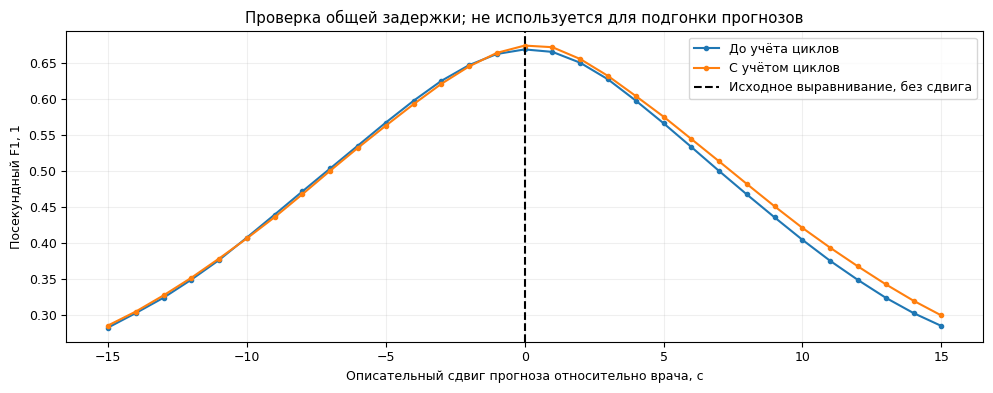

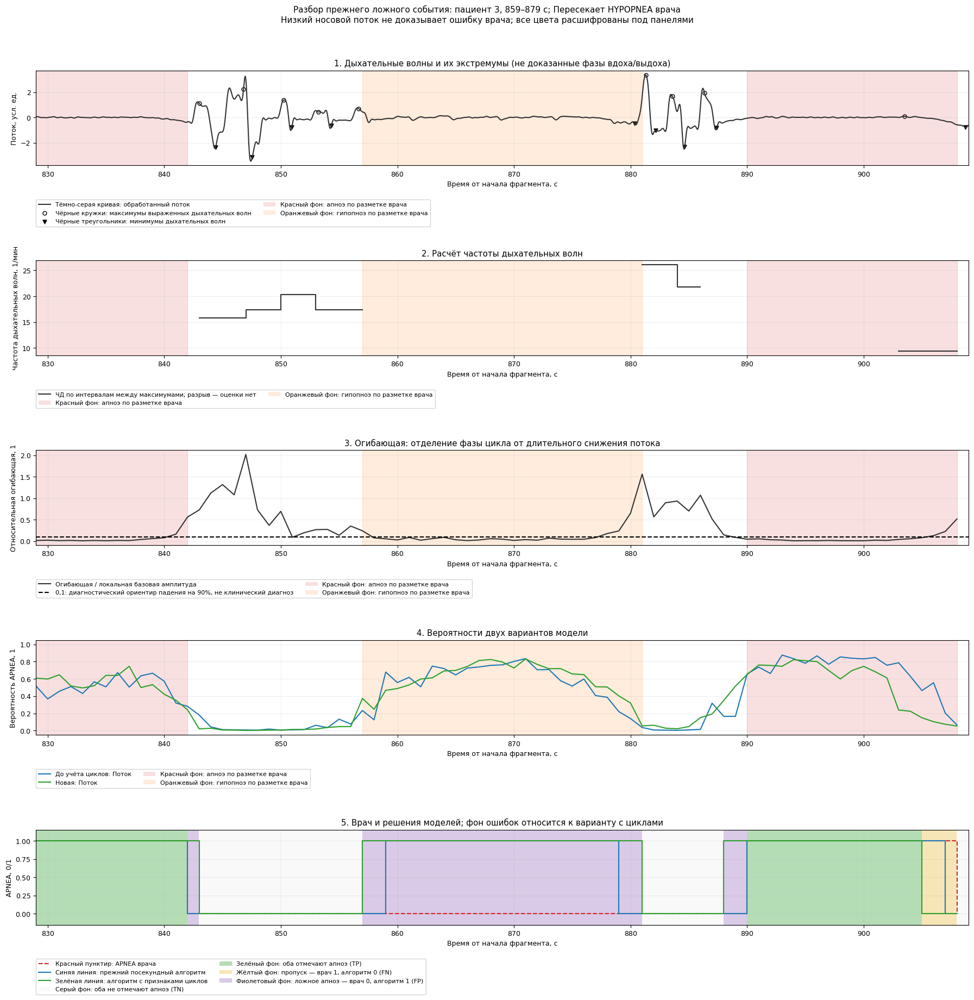

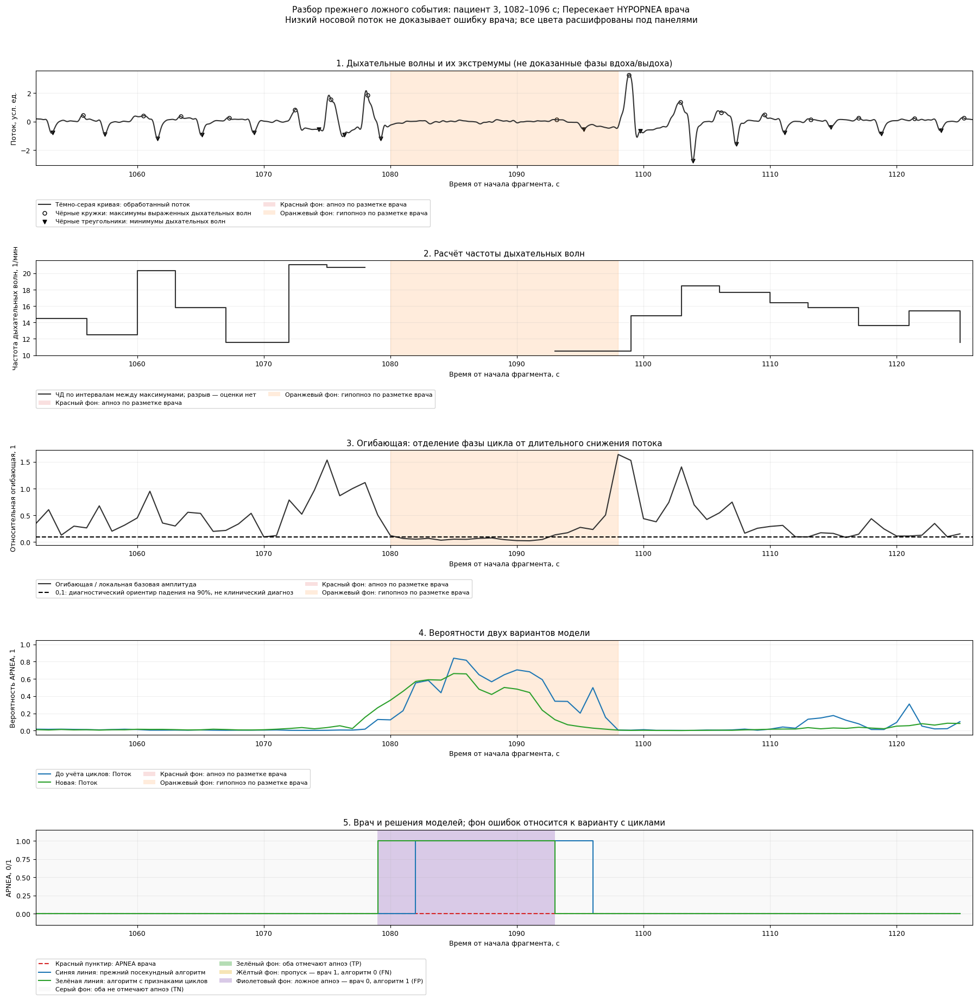

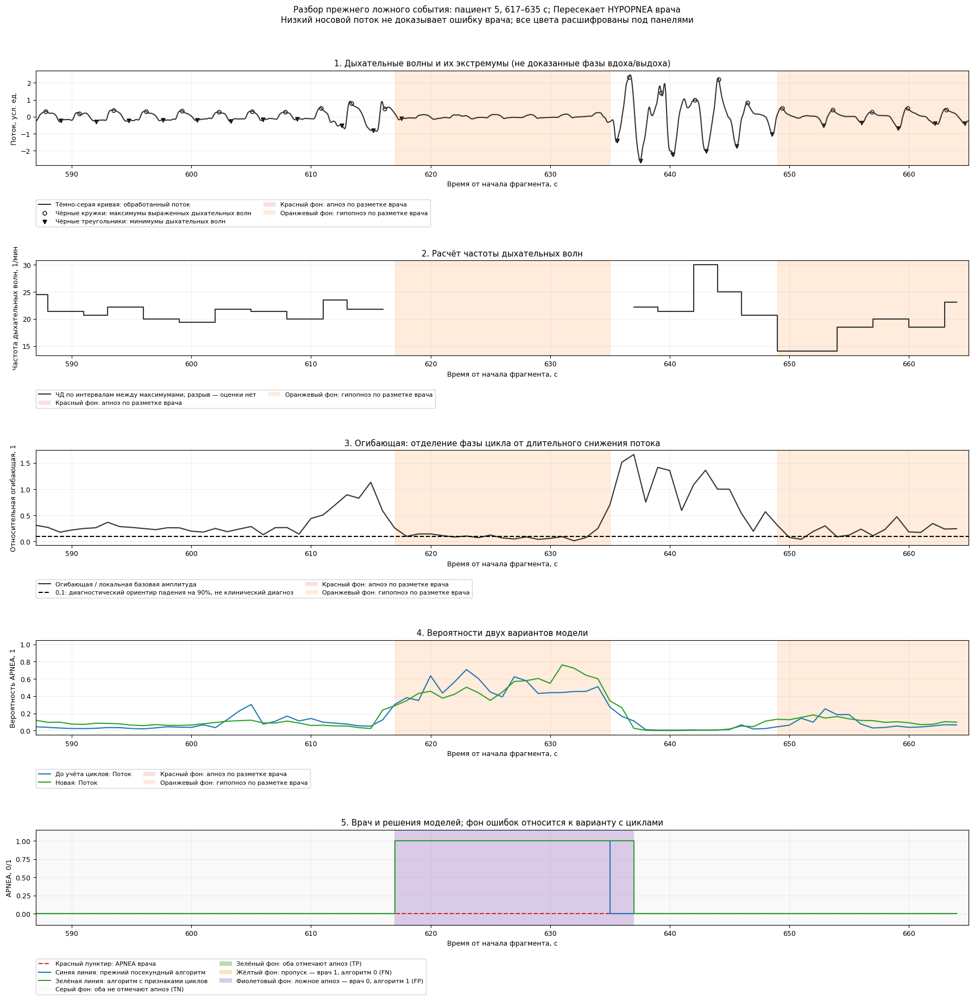

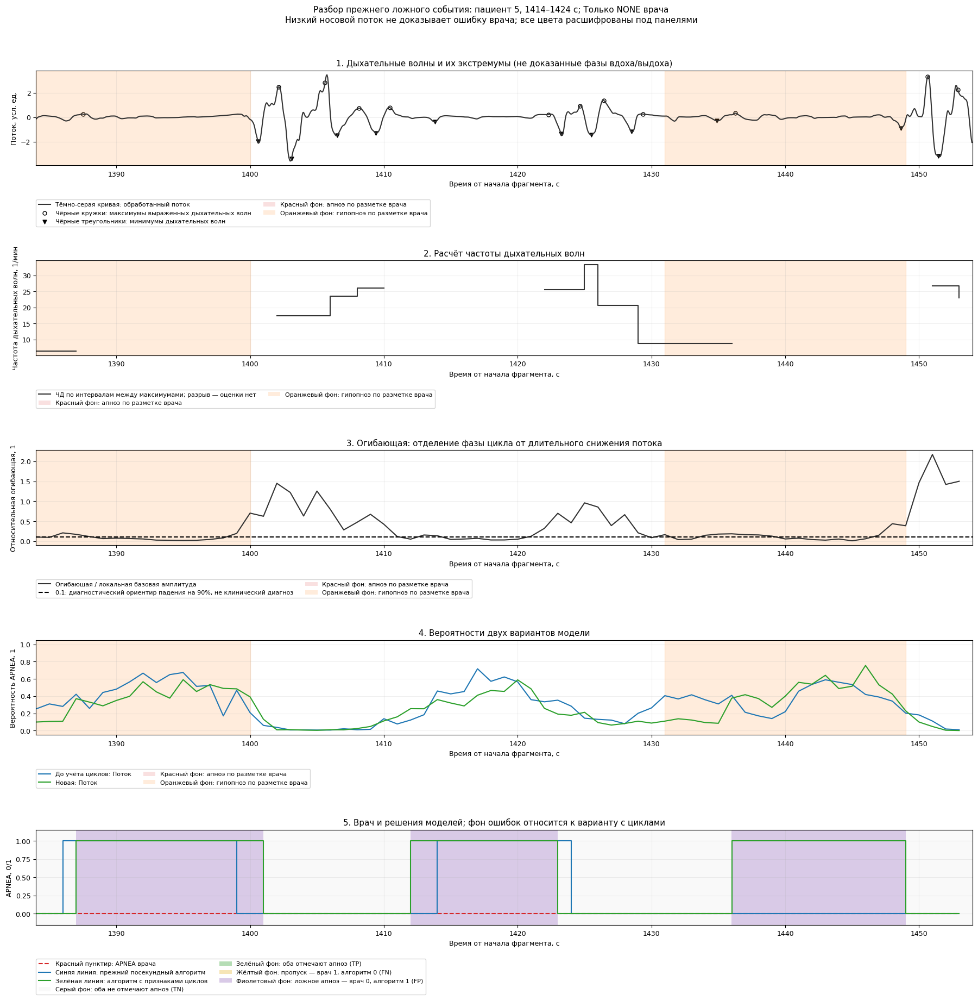

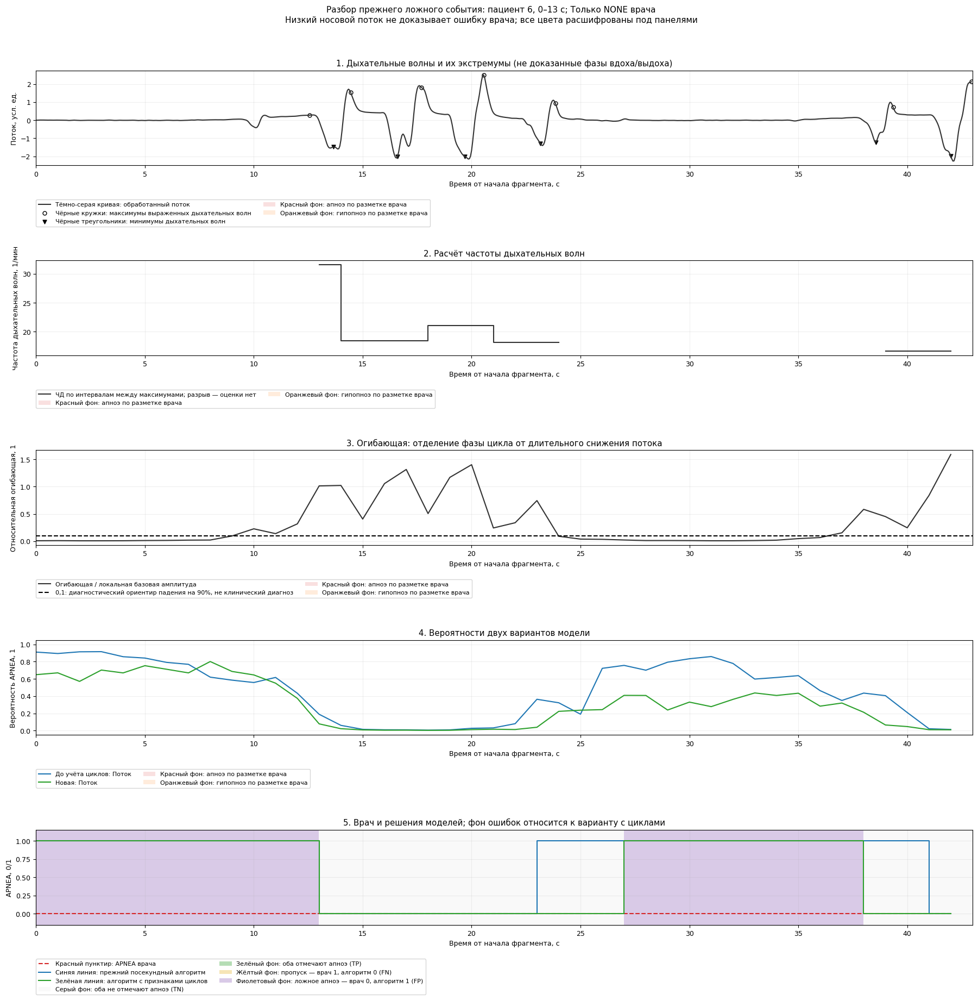

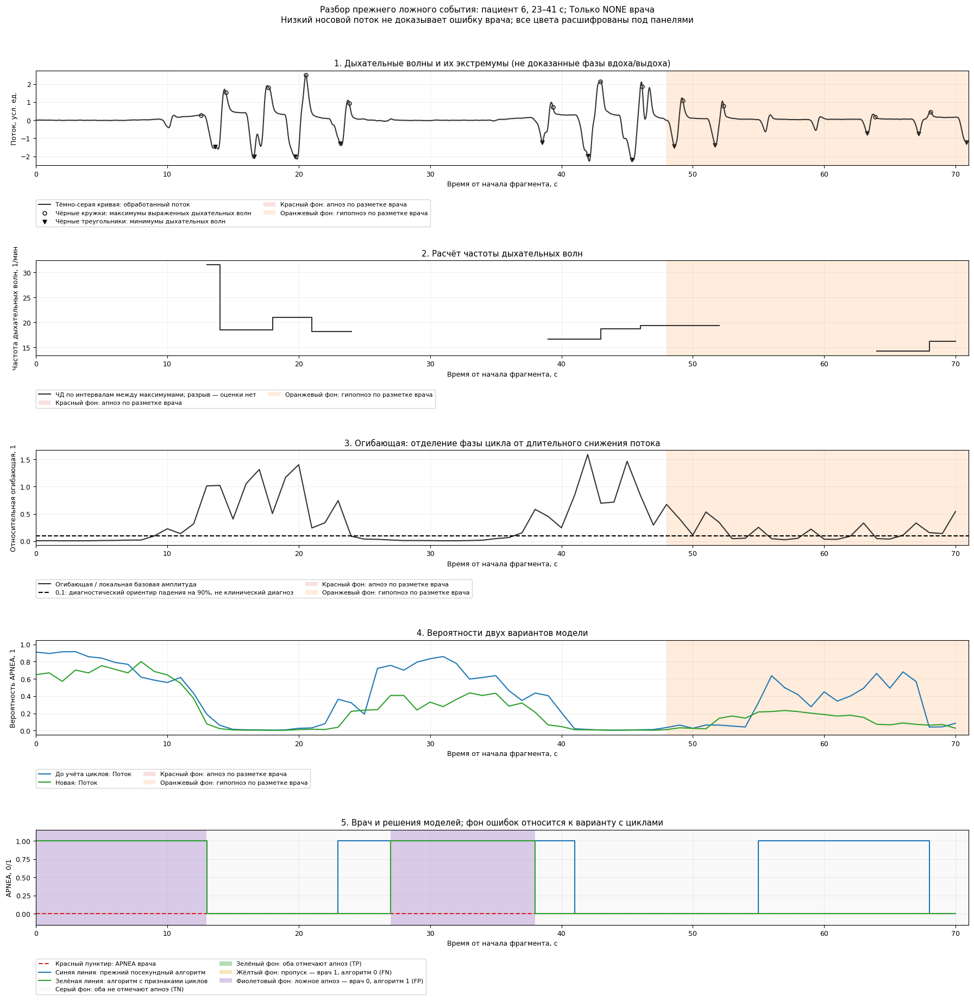

PASS: тестовый синус 0,25 Гц → 15 дыхательных волн/мин; клиническая точность этим не доказывается.


In [12]:
audit_rows=[];lag_rows=[]
for variant,dd_all in [('До учёта циклов',METHOD_PREDS['До учёта циклов: Поток']),('С учётом циклов',preds['Поток'])]:
    for pid in patients:
        ix=np.flatnonzero(groups==pid);yy=y[ix].astype(bool);dd=dd_all[ix];labels=frame.label.to_numpy()[ix]
        ratio=processed[pid]['env_ratio'];br=processed[pid]['breaths'];pt=br['peaks']/20
        _,ev=match_events(yy,dd,np.full(len(ix),pid),.3)
        for _,r in ev.iterrows():
            if r.status!='false_alarm':continue
            a,b=int(r.algorithm_start),int(r.algorithm_end);ap_s=int(yy[a:b].sum());hy_s=int((labels[a:b]=='HYPOPNEA').sum())
            cat='Частично пересекает APNEA' if ap_s else ('Пересекает HYPOPNEA врача' if hy_s else 'Только NONE врача')
            peaks=pt[(pt>=a)&(pt<b)];gaps=np.diff(np.r_[a,peaks,b])
            low=ratio[a:b]<.1;longest=max([d-c for c,d in spans(low)],default=0)
            audit_rows.append(dict(variant=variant,patient=pid,start_s=a,end_s=b,duration_s=b-a,category=cat,
                doctor_APNEA_s=ap_s,doctor_HYPOPNEA_s=hy_s,prominent_waves=len(peaks),max_wave_gap_s=float(gaps.max()),
                median_env_ratio=float(np.median(ratio[a:b])),longest_90pct_drop_s=longest))
    for shift in range(-15,16):
        shifted=np.zeros(len(y),bool)
        for pid in patients:
            ix=np.flatnonzero(groups==pid)
            shifted[ix]=np.interp(np.arange(len(ix))-shift,np.arange(len(ix)),dd_all[ix],left=0,right=0)>=.5
        lag_rows.append(dict(variant=variant,shift_s=shift,F1=f1_score(y,shifted)))
fp_audit=pd.DataFrame(audit_rows);lag_audit=pd.DataFrame(lag_rows)
fp_audit.to_csv(RESULTS/'false_alarm_audit.csv',index=False);lag_audit.to_csv(RESULTS/'lag_audit.csv',index=False)
print('Каждое лишнее событие отнесено к одной категории; пересечение с HYPOPNEA не означает APNEA.')
display(fp_audit.groupby(['variant','category']).agg(events=('start_s','size'),seconds=('duration_s','sum'),median_waves=('prominent_waves','median'),median_longest_gap_s=('max_wave_gap_s','median')).round(2))
display(fp_audit.head(25).round(2))
print('Сравнение до/после добавления циклов; меньше FP может сопровождаться большим FN:')
display(metrics.loc[['До учёта циклов: Поток','Новая: Поток'],['second_F1','event_F1','event_TP','event_FP','event_FN','sensitivity','precision']].round(4))
fig,ax=plt.subplots(figsize=(10,4))
for variant,sub in lag_audit.groupby('variant'):
    ax.plot(sub.shift_s,sub.F1,'o-',ms=3,label=variant)
ax.axvline(0,color='black',ls='--',label='Исходное выравнивание, без сдвига')
ax.set(xlabel='Описательный сдвиг прогноза относительно врача, с',ylabel='Посекундный F1, 1',title='Проверка общей задержки; не используется для подгонки прогнозов')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();save_show(fig,'lag_diagnostic')
# Reproducible illustration selection: first three old false alarms in each category.
examples=pd.concat([sub.sort_values(['patient','start_s']).head(3) for _,sub in fp_audit[fp_audit.variant=='До учёта циклов'].groupby('category')])
for _,r in examples.iterrows():
    pid=int(r.patient);start=int(r.start_s);end=int(r.end_s);a=max(0,start-30);b=min(1800,end+30)
    ix=np.flatnonzero(groups==pid);pr=processed[pid];br=pr['breaths'];tt=np.arange(a,b);labels=patients[pid]['event'][a:b].astype(str)
    fig,axs=plt.subplots(5,1,figsize=(18,19))
    axs[0].plot(np.arange(a*20,b*20)/20,pr['flow'][a*20:b*20],color='#333333',label='Тёмно-серая кривая: обработанный поток')
    pk=br['peaks'];pk=pk[(pk>=a*20)&(pk<b*20)];tr=br['troughs'];tr=tr[(tr>=a*20)&(tr<b*20)]
    axs[0].scatter(pk/20,pr['flow'][pk],s=25,facecolors='white',edgecolors='black',label='Чёрные кружки: максимумы выраженных дыхательных волн')
    axs[0].scatter(tr/20,pr['flow'][tr],marker='v',s=25,color='black',label='Чёрные треугольники: минимумы дыхательных волн')
    axs[0].set_ylabel('Поток, усл. ед.')
    axs[1].step(tt,br['rate'][a:b],where='post',color='#333333',label='ЧД по интервалам между максимумами; разрыв — оценки нет')
    axs[1].set_ylabel('Частота дыхательных волн, 1/мин')
    axs[2].plot(tt,pr['env_ratio'][a:b],color='#333333',label='Огибающая / локальная базовая амплитуда')
    axs[2].axhline(.1,color='black',ls='--',label='0,1: диагностический ориентир падения на 90%, не клинический диагноз')
    axs[2].set_ylabel('Относительная огибающая, 1')
    for name,color in [('До учёта циклов: Поток','#1f77b4'),('Новая: Поток','#2ca02c')]:
        axs[3].plot(tt,METHOD_PROBS[name][ix][a:b],color=color,label=name)
    axs[3].set(ylabel='Вероятность APNEA, 1',ylim=(-.05,1.05))
    yy=y[ix][a:b].astype(bool);dd=preds['Поток'][ix][a:b];err_background(axs[4],yy,dd,start=a,scale=1)
    axs[4].step(tt,yy,where='post',color='#d62728',ls='--',label='Красный пунктир: APNEA врача')
    axs[4].step(tt,METHOD_PREDS['До учёта циклов: Поток'][ix][a:b],where='post',color='#1f77b4',label='Синяя линия: прежний посекундный алгоритм')
    axs[4].step(tt,dd,where='post',color='#2ca02c',label='Зелёная линия: алгоритм с признаками циклов')
    axs[4].set(ylabel='APNEA, 0/1',ylim=(-.15,1.15))
    for ax in axs[:4]:shade_doctor(ax,labels,offset=a,scale=1)
    for ax,title in zip(axs,['1. Дыхательные волны и их экстремумы (не доказанные фазы вдоха/выдоха)','2. Расчёт частоты дыхательных волн','3. Огибающая: отделение фазы цикла от длительного снижения потока','4. Вероятности двух вариантов модели','5. Врач и решения моделей; фон ошибок относится к варианту с циклами']):
        ax.set(title=title,xlabel='Время от начала фрагмента, с',xlim=(a,b));ax.grid(alpha=.2);panel_legend(ax)
    fig.suptitle(f'Разбор прежнего ложного события: пациент {pid}, {start}–{end} с; {r.category}\n'
                 'Низкий носовой поток не доказывает ошибку врача; все цвета расшифрованы под панелями',fontsize=11)
    fig.tight_layout(rect=(0,0,1,.96));save_show(fig,f'false_alarm_patient_{pid}_{start}')
# Label-free sanity check on a known periodic signal. This validates rate calculation only.
tt=np.arange(120*20)/20;_,sinus=respiratory_cycles(np.sin(2*np.pi*.25*tt))
assert abs(np.nanmedian(sinus['rate'][10:-10])-15)<.1
print('PASS: тестовый синус 0,25 Гц → 15 дыхательных волн/мин; клиническая точность этим не доказывается.')


## Сохранение результатов и границы выводов

Сохраняются посекундные вероятности/решения, соответствия событий, метрики каждого пациента, доверительные интервалы и все рисунки. Границы `start_s/end_s` задаются как полуинтервалы [start, end), время от начала данного фрагмента. Вероятности и прогнозы в CSV только внешние OOF.

Если нет ни положительных секунд, ни положительных прогнозов, F1 обозначается NaN, а не ошибкой обнаружения. Улучшение оформления не является улучшением модели. Если у ФПГ низкая точность, это сохраняется в результатах. Если сочетание хуже потока, его нельзя рекомендовать только потому, что оно использует два канала. Неопределённость причин ошибок не позволяет объявлять врачебные метки неправильными. Порог по F1 не является клинически утверждённой рабочей точкой.

Текущий анализ повторно использует небольшой набор OSASUD. Нужны нетронутые пациенты, полные ночи и независимая проверка разметки/синхронизации. Ни подбор по тестовым меткам, ни сдвиги графиков, ни удаление неудобных событий не применяются. Данные полного исходного pickle не загружаются, настройки рабочей среды не публикуются.


In [13]:
pred_table=frame[['patient','time_s','label','target']].copy()
for name in probs:
    pred_table[name+'_probability']=probs[name]
    if name=='ФПГ':
        pred_table['ФПГ_candidate_APNEA']=preds[name].astype(int)
        pred_table['ФПГ_quality_accepted']=ppg_accepted
        pred_table['ФПГ_automatic_APNEA']=np.where(ppg_accepted,preds[name].astype(float),np.nan)
    else:pred_table[name+'_APNEA']=preds[name].astype(int)
pred_table.to_csv(RESULTS/'second_predictions.csv',index=False)
# Машинно-читаемые таблицы + рисунки для проверки и подготовки статьи.
archive=Path('OSASUD_event_results.zip')
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as zz:
    for p in sorted(RESULTS.iterdir()):
        if p.is_file():zz.write(p,arcname=p.name)
print('Полное выполнение завершено за',round(time.time()-STARTED,1),'с')
print('Результаты:',RESULTS.resolve());print('Архив:',archive.resolve())
display(FileLink(str(archive)))

breath_rows=[]
for pid,pr in processed.items():
    for t,rate in enumerate(pr['breaths']['rate']):breath_rows.append(dict(patient=pid,time_s=t,respiratory_rate=rate))
pd.DataFrame(breath_rows).to_csv(RESULTS/'respiratory_rate.csv',index=False)
# Include the added respiratory diagnostics in the local archive.
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as zz:
    for p in sorted(RESULTS.iterdir()):
        if p.is_file():zz.write(p,arcname=p.name)


Полное выполнение завершено за 231.5 с
Результаты: /workspace/work/redesign/OSASUD_event_results
Архив: /workspace/work/redesign/OSASUD_event_results.zip


/workspace/work/redesign/OSASUD_event_results.zip